# EDA bình luận YouTube vừa crawl

**Mục đích:** đọc bộ bình luận crawler vừa ghi ra, kiểm tra dữ liệu gốc (Level 0) rồi làm sạch kỹ thuật (Level 1). Cập nhật lần cuối: 2026-11-11.

**Nội dung**

1. Đọc dữ liệu
2. Level 0 – Raw Data Audit: crawl được gì (video, độ dài, trùng lặp, emoji, URL, ngôn ngữ, thời gian, đăng dồn)
3. Level 1 – Technical Cleaning: comment null, HTML entities, ký tự điều khiển, Unicode không thống nhất, xuống dòng bất thường, khoảng trắng dư
4. In danh sách bình luận để xem
5. Khía cạnh được nhắc tới: ước lượng nhanh bằng từ khóa

**Cách chạy:** chọn kernel `.venv` (góc phải trên), rồi *Run All*. Notebook không sửa file dữ liệu gốc. Kết quả làm sạch nằm ở cột mới `text_clean`, cột `text` giữ nguyên.

### Cài đặt chung

**Ô code làm gì:** nạp thư viện, tìm đường dẫn tới file dữ liệu, chỉnh pandas để in đủ nội dung bình luận.

`N_SHOW` là số bình luận in ra ở mỗi danh sách. Muốn xem nhiều hơn thì tăng số này.

In [14]:
import html
import re
import sys
import unicodedata
from pathlib import Path

import pandas as pd
from IPython.display import display


def tim_goc_repo() -> Path:
    """Đi ngược lên từ thư mục hiện tại tới khi gặp config/pipeline.yaml, để mở notebook từ đâu cũng chạy được."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "config" / "pipeline.yaml").exists():
            return p
    raise FileNotFoundError("Không tìm thấy gốc repo (thư mục có config/pipeline.yaml)")


ROOT = tim_goc_repo()
DATA_PATH = ROOT / "src" / "ingest" / "data" / "raw" / "comments.jsonl"   # chỗ crawler ghi ra

N_SHOW = 50   # số bình luận in ra ở mỗi danh sách

pd.set_option("display.max_colwidth", None)   # không cắt ngắn bình luận dài
pd.set_option("display.max_rows", 1000)
print("File dữ liệu:", DATA_PATH)

File dữ liệu: c:\Users\Admin\Desktop\He_thong_phan_tan_phan_tich_nguon_binh_luan_sau_ra_mat_dien_thoai_tai_viet_nam\src\ingest\data\raw\comments.jsonl


## 1. Đọc dữ liệu

**Để làm gì:** nạp toàn bộ bình luận vào một bảng (DataFrame) để làm sạch.

**Ô code làm gì:**
- Đọc `comments.jsonl`, mỗi dòng là một bình luận dạng JSON, đúng contract `comment-event` v3.
- Đọc nguyên trạng: `dtype=False`, `convert_dates=False` để pandas không tự đổi kiểu cột (mã, ngày giờ giữ là chuỗi).
- In số dòng, danh sách cột kèm kiểu và số ô trống, rồi 5 bình luận đầu.

**Đọc kết quả:** cột `text` là nội dung bình luận, thứ Level 1 sẽ làm sạch. Ô trống ở `parent_id`, `parent_text` là bình thường: bình luận gốc không có comment cha.

In [15]:
df = pd.read_json(DATA_PATH, lines=True, dtype=False, convert_dates=False)
print(f"{len(df):,} bình luận × {df.shape[1]} cột")

pd.set_option("display.max_columns", None)    # hiện đủ mọi cột, không ẩn bằng "..."
pd.set_option("display.max_colwidth", None)   # không cắt ngắn bình luận dài
pd.set_option("display.width", None)

# Kiểu và số ô trống của từng trường
display(pd.DataFrame({
    "kiểu": df.dtypes.astype(str),
    "số ô trống (null)": df.isna().sum(),
}))

# Xem dữ liệu theo trang, mỗi trang đủ mọi trường
TRANG = 0        # trang 0 = dòng 0–99, trang 1 = dòng 100–199...; đổi số này rồi chạy lại để lật trang
CO_TRANG = 100   # số dòng mỗi trang
AN_COT = ["author_name"]   # tên kênh người bình luận (dữ liệu cá nhân); đổi thành [] nếu muốn xem
dau, cuoi = TRANG * CO_TRANG, (TRANG + 1) * CO_TRANG
print(f"Dòng {dau:,}–{min(cuoi, len(df)) - 1:,} / {len(df):,}")
display(df.drop(columns=AN_COT, errors="ignore").iloc[dau:cuoi])

473,786 bình luận × 21 cột


,kiểu,số ô trống (null)
comment_id,str,0
video_id,str,0
parent_id,str,271375
parent_text,str,271375
model,str,0
source,str,0
text,str,0
text_norm,str,0
author_hash,str,0
published_at,str,0


Dòng 0–99 / 473,786


,comment_id,video_id,parent_id,parent_text,model,source,text,text_norm,author_hash,published_at,like_count,reply_count,fetched_at,ingested_at,schema_version,author_channel_created_at,author_video_count,author_subscriber_count,author_is_creator,author_fetched_at
0,UghiyJ6LK_7a4XgCoAEC,9SmOJHZTkC4,NaN,NaN,ip6,youtube,Sony xperia z3...quá đẹp,,069722f199073a1f8b0223df1aa448cd79e0695bd87f82fd737f9f892520bdcb,2014-10-16T16:10:26Z,0,0.0,2026-10-19T09:33:30Z,2026-10-19T09:33:30Z,3,2013-09-20T23:42:13Z,3.0,29.0,False,2026-11-06T13:09:50Z
1,UggBOnKLW2AIoHgCoAEC,9SmOJHZTkC4,NaN,NaN,ip6,youtube,Mình cũng đã dùng cả ip và note. Nhưng nói thật là vẫn thích dùng ip hơn. Nhưng thích 5s chứ k phải 6 hay 6 plus. 5s gọn mà tính năng cũng k thua kém 6 hay 6 plus là bao. Dùng màn hình to chỉ thích mỗi xem phim và chơi game chứ còn thao tác 1 tay thì khó thôi rồi. Chưa kể nằm mà chơi game hay xem phim dơ điện thoại màn hình nhỏ lên chẳng may mà ngủ quên mất nó có rơi vào mặt thì đỡ đau hơn là màn hình to.😁😁😁😁😁😁,,ee90f58adca90151f95bb1470e9793f7fa52a44c775f57a49e2e3691c7264934,2014-10-16T05:16:37Z,0,0.0,2026-10-19T09:33:30Z,2026-10-19T09:33:30Z,3,2013-03-10T04:03:37Z,10.0,4.0,False,2026-11-06T13:07:20Z
2,Uggc_0MHFlz_HXgCoAEC,9SmOJHZTkC4,NaN,NaN,ip6,youtube,"Theo em thì người ta bỏ cả cục tiền để mua cái thương hiệu thôi các bác ạ chứ ios còn nhiều điểm chưa bằng android lắm. hiệu năng thì em không nói nhưng về ứng dụng, phần mềm thì ios thua xa android.\nSS note 4 cũng sắp bán nhỉ? em nghĩ có tiền thì mua té con note 4 cho nó mát ruột, nó chạy đa nhiệm thì quá tuyệt (xem review thấy thế) ứng dụng thì hơn hẳn ip6 hay ip6+ rồi. :)) còn cả cái s-pen nữa, hai mua con z3, oppo F7 đi cho đáng đồng tiền bát gạo, như e sinh viên nghèo thì xài con Zenphone 5 thấy mát lắm rồi, ít nhất nó cũng chơi được fifa vs asphalt 8 mà k lác giật.\nCòn bây h mà bỏ đống tiền ra để mua iphone thì quá ngu đấy mấy bác, em nói thật, giờ ra đường thấy cô lao công cũng cầm ip5 rồi :3 em thì k phải em coi thường mấy cô nhân công không có tiền mà đua đòi mà ý em nói là ip h nó quá phổ biết rồi, nhà nhà có, người người có, nó giống như cuộn giấy vệ sinh ấy, nhà ai chả có, chứ sang chảnh gì đâu.\ný kiên cá nhân thôi, em cũng chỉ nói thế, mấy bác hiểu sao thì hiểu, chứ đừng bỏ tiền ra mua cái thương hiệu làm gì?\nThân ái!",,b842ee1658058d93f5e927f623e11cfec1e43b89840f945d31173327bce5c655,2014-10-15T14:11:02Z,1,1.0,2026-10-19T09:33:30Z,2026-10-19T09:33:30Z,3,2012-04-05T07:22:20Z,0.0,3.0,False,2026-11-06T13:03:58Z
3,UgjriuIJjyqfMngCoAEC,9SmOJHZTkC4,NaN,NaN,ip6,youtube,minh khong thich,,a5a92da9cd601963fc493e5fb6f57074890373052b23225529d13f12a932b149,2014-10-15T13:11:38Z,0,0.0,2026-10-19T09:33:30Z,2026-10-19T09:33:30Z,3,2012-07-13T05:59:51Z,2.0,0.0,False,2026-11-06T13:11:25Z
4,Ugh7M18cWnLzEngCoAEC,9SmOJHZTkC4,NaN,NaN,ip6,youtube,"nói thật suy nghĩ của bản thân đéo phải fan thằng nào nhưng mà mỗi lần Apple ra đth mới Android Phone Fan cứ làm loạn hết cmn lên.đm chửi ì xèo cái L gì mà chỉ đc cái thương hiệu, người Việt chỉ thích ra oai.bỏ mấy chục triệu mua iPhone ............cứ như ai đó đ* bạn gái tụi m,TQ trả lại đảo cho VN, IS thôi chặt đầu khủng bố con tin, U19 VN vô đich WorldCup.ngta thích thì ngta mua ảnh hưởng tới tiền ăn sáng của chúng m à ??? khi S5 One M8 z3 ra có luôn khuyết điểm chúng m có thấy Fan thằng iOs Phone nào chửi chúng m ko ??? t đéo thích thằng nào hết nhưng cái kho ứng dụng của Apple và sự mươt mà của nó là đủ để làm con ngta khoái rồi.đéo phải tắt máy reset giải phóng ram.đéo ham rồi",,01795f9df14c10d3d22752cb146f4ca3ae64a199fcedfa8ec7d762691b3f2527,2014-10-13T14:21:24Z,0,0.0,2026-10-19T09:33:30Z,2026-10-19T09:33:30Z,3,2013-08-06T06:18:08Z,0.0,0.0,False,2026-11-06T13:04:53Z
5,Ugh4RPIvBTL7-HgCoAEC,9SmOJHZTkC4,NaN,NaN,ip6,youtube,iphone cung ap dung ti le vang uh,,6f623b22d74d6c98cef1a035dd645d2236c6f71c24edf33b4d7398510e2306a2,2014-10-13T10:59:26Z,0,0.0,2026-10-19T09:33:30Z,2026-10-19T09:33:30Z,3,2013-07-21T05:45:20Z,1.0,2.0,False,2026-11-06T13:03:14Z
6,Ugjx_OcS

## 2. Level 0 – Raw Data Audit

**Để làm gì:** hiểu mình đã crawl được những gì **trước khi sửa bất cứ thứ gì**. Level 0 chỉ đọc và đếm trên cột `text` gốc, không thay đổi dữ liệu.

| Mục | Câu hỏi |
|---|---|
| 2.1 | Crawl được bao nhiêu video, mỗi video bao nhiêu bình luận, mỗi máy bao nhiêu |
| 2.2 | Bao nhiêu bình luận rỗng |
| 2.3 | Bao nhiêu bình luận trùng lặp |
| 2.4 | Bình luận thường dài bao nhiêu |
| 2.5 | Bao nhiêu bình luận chỉ có emoji |
| 2.6 | Bao nhiêu bình luận chỉ có URL |
| 2.7 | Bao nhiêu bình luận tiếng Việt, tiếng Anh, ngôn ngữ khác |
| 2.8 | Bình luận trải dài bao lâu, có ngày nào tăng đột biến |
| 2.9 | Có nhiều bình luận giống nhau đăng dồn trong thời gian ngắn không |

Cuối mục có bảng tổng hợp các con số chính.

In [16]:
import matplotlib.pyplot as plt
import numpy as np

raw = df["text"].fillna("").astype(str)   # nội dung gốc (null coi như rỗng); chỉ đọc, không sửa
thoi_gian = pd.to_datetime(df["published_at"], utc=True, errors="coerce").dt.tz_convert("Asia/Ho_Chi_Minh")
AUDIT = {}   # con số chính của từng mục, in thành bảng ở cuối Level 0
print(f"{len(df):,} bình luận | thời điểm đăng đọc được: {thoi_gian.notna().sum():,}")

473,786 bình luận | thời điểm đăng đọc được: 473,786


### 2.1 Video và số bình luận mỗi video

**Ô code làm gì:**
- Đếm số video có bình luận, và mỗi video có bao nhiêu bình luận (trung bình, trung vị, các phân vị).
- In `N_SHOW` video nhiều bình luận nhất, kèm tên kênh và tiêu đề lấy từ `videos.jsonl` (nếu có file này).
- Vẽ phân bố số bình luận mỗi video. Trục ngang dùng thang log vì vài video rất đông, còn đa số video ít bình luận.
- Đếm số bình luận và số video theo từng máy (`model`). Video so sánh nhiều máy có `model` dạng `a|b`.

**Đọc kết quả:**
- Trung vị nhỏ hơn trung bình nhiều nghĩa là vài video "hút" phần lớn bình luận.
- Video có quá ít bình luận (dưới 10) thì đóng góp ít cho phân tích.

Số video có bình luận: 4,682 | video có < 10 bình luận: 1,027


,bình luận / video
count,4682.0
mean,101.2
std,182.2
min,1.0
25%,12.0
50%,50.0
75%,134.8
90%,255.0
99%,619.2
max,5803.0


videos.jsonl có 5,167 video; 507 video trong đó không có bình luận nào trong comments.jsonl

50 video nhiều bình luận nhất:


,số bình luận,channel_title,title,published_at
video_id,,,,
tR2ne0OReGY,5803,Vật Vờ Studio,[GA] 3 ĐIỀU ĐÁNG TIỀN NHẤT trên S20 Ultra,2020-03-05T13:58:31Z
t1vCy2uQWJw,5543,Schannel,NHẬN GALAXY J7 PRO MIỄN PHÍ khi trả lời câu hỏi về NOTE 8 !!,2017-09-29T13:01:02Z
FbKYwezqjHU,2365,Schannel,SHOCK ! TẶNG iPhone X trị giá 30 triệu MIỄN PHÍ nhân dịp 900K subscribe từ iFind,2017-11-17T11:53:37Z
LKnsKK2VZCs,2287,ĐAM MÊ CÔNG NGHỆ,"UNBOX Galaxy A52 5G: SNAP 750G, 120HZ, chống nước, GIÁ RẺ NHẤT (G.A QUÀ 4TR)!!!",2021-04-10T12:17:22Z
qReOShDjjKI,1535,Vật Vờ Studio,So sánh hiệu năng iPhone 11 Pro Max và Galaxy Note 10+: Apple A13 vs Exynos 9825,2019-09-21T05:32:02Z
jgoZpbulcOY,1432,vivo Việt Nam,vivo V21 5G x @J97imjack Jack | Trọn Từng Phút Đẹp Từng Giây,2021-05-01T17:43:51Z
u8ozBBEyiPY,1332,Vinh Xô,"So Sánh Hiệu Năng, Nhiệt Độ Xiaomi 17 Pro Max và iPhone 17 Pro Max: mạnh khủng khiếp quá 🤯",2025-09-30T04:50:48Z
_G4nbQ4cqe8,1203,Schannel,Speedtest iPhone 8 Plus vs Galaxy Note 8: Ông vua hiệu năng 2017 thuộc về... [ENGSUB],2017-09-21T22:19:31Z
OzIBdMlccAE,1182,Vinh Xô,So sánh CAMERA siêu chống rung iPhone 14 Pro Max và Galaxy S22 Ultra: khác biệt quá lớn,2022-09-18T03:54:45Z


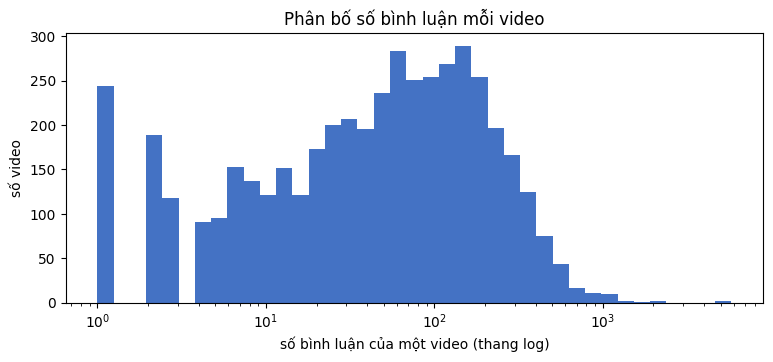


Theo máy: 148 giá trị model


,so_binh_luan,so_video
model,,
ip14prm,22008,159
s20ultra,19207,81
ip15prm,17516,131
s23u,17021,178
ip13prm,15137,91
ipx,14303,108
ip17prm,14198,137
ip11pro,13516,92
s24u,13378,147


In [17]:
VIDEOS_PATH = ROOT / "src" / "ingest" / "data" / "raw" / "videos.jsonl"

cmt_moi_video = df.groupby("video_id").size().sort_values(ascending=False)
AUDIT["Số video có bình luận"] = len(cmt_moi_video)
AUDIT["Video có < 10 bình luận"] = int((cmt_moi_video < 10).sum())
print(f"Số video có bình luận: {len(cmt_moi_video):,} | video có < 10 bình luận: {(cmt_moi_video < 10).sum():,}")
display(cmt_moi_video.describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_frame("bình luận / video"))

vd = None
if VIDEOS_PATH.exists():
    vd = (pd.read_json(VIDEOS_PATH, lines=True, dtype=False, convert_dates=False)
            .drop_duplicates("video_id", keep="last").set_index("video_id"))   # mỗi video lấy bản chụp mới nhất
    khong_cmt = (~vd.index.isin(cmt_moi_video.index)).sum()
    print(f"videos.jsonl có {len(vd):,} video; {khong_cmt:,} video trong đó không có bình luận nào trong comments.jsonl")

top = cmt_moi_video.head(N_SHOW).rename("số bình luận").to_frame()
if vd is not None:
    top = top.join(vd[["channel_title", "title", "published_at"]])
print(f"\n{N_SHOW} video nhiều bình luận nhất:")
display(top)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(cmt_moi_video, bins=np.logspace(0, np.log10(cmt_moi_video.max() + 1), 40), color="#4472c4")
ax.set_xscale("log")
ax.set_xlabel("số bình luận của một video (thang log)")
ax.set_ylabel("số video")
ax.set_title("Phân bố số bình luận mỗi video")
plt.show()

theo_may = (df.groupby("model").agg(so_binh_luan=("comment_id", "size"), so_video=("video_id", "nunique"))
              .sort_values("so_binh_luan", ascending=False))
print(f"\nTheo máy: {len(theo_may):,} giá trị model")
display(theo_may)

### 2.2 Bình luận rỗng

**Ô code làm gì:** đếm bình luận có `text` null, chuỗi rỗng, hoặc chỉ có khoảng trắng, rồi in danh sách.

Bình luận chỉ chứa ký tự vô hình (vd zero-width space) chưa tính ở đây vì nhìn bằng mắt không thấy. Level 1 (B7) sẽ bắt loại này.

In [18]:
rong = raw.str.strip() == ""
AUDIT["Bình luận rỗng"] = int(rong.sum())
print(f"Bình luận rỗng: {rong.sum():,} / {len(df):,} ({100 * rong.mean():.3f}%)")
display(df.loc[rong, ["comment_id", "video_id", "model", "published_at"]].head(N_SHOW))

Bình luận rỗng: 42 / 473,786 (0.009%)


,comment_id,video_id,model,published_at
34,UgjbOdscgJD2yHgCoAEC,9SmOJHZTkC4,ip6,2014-09-23T05:54:33Z
58,UgiIqSCXBt5YdXgCoAEC,9SmOJHZTkC4,ip6,2014-09-22T08:38:11Z
1073,UgjxaDGwkIYC-3gCoAEC,2I74I1hNfCo,note4,2014-11-07T06:31:33Z
1239,UghrV9A4qnP0FngCoAEC,2I74I1hNfCo,note4,2014-11-06T13:46:26Z
1253,Ughu11aZQN_2SHgCoAEC,2I74I1hNfCo,note4,2014-11-06T13:39:06Z
16560,UgjZkwtATSIqRHgCoAEC,PYPeo0RfGA8,note8,2017-09-29T02:51:25Z
76115,UgzAYGX2_TjsrTBsR-R4AaABAg.9g71aopSA5R9g75ZK5M2bO,uh3LzLnGJM0,ip14prm,2022-09-18T13:31:06Z
84805,UgwaUrKazJb56U-szsB4AaABAg,wLmIfDX2YJo,s23u,2023-02-05T14:43:27Z
91564,UgxM7m_4IhnA2B76ZaZ4AaABAg,GuwxQLtkbdY,xiaomi13u,2023-04-26T05:31:28Z
109810,UghOblKNP43AtXgCoAEC,x0ecYuH2dwk,s5,2014-04-26T06:42:00Z


### 2.3 Bình luận trùng lặp

**Ô code làm gì:** đếm 3 kiểu trùng.
1. **Trùng `comment_id`:** cùng một bình luận bị ghi hai lần. Đây là lỗi crawl, phải bằng 0.
2. **Trùng nội dung:** khác `comment_id` nhưng nội dung giống hệt nhau (so nguyên văn, bỏ qua bình luận rỗng).
3. **Một người đăng lại cùng nội dung:** cùng `author_hash` và cùng nội dung, xuất hiện từ 2 lần trở lên. Đây là dấu hiệu spam hoặc seeding.

Sau đó in `N_SHOW` nội dung bị lặp nhiều nhất, kèm số lần, số video, số người đăng.

**Đọc kết quả:**
- Câu ngắn phổ biến ("hay", "đẹp quá") trùng nhau là tự nhiên.
- Đáng chú ý là câu **dài** mà trùng nhiều lần, hoặc trùng trên nhiều video.

In [19]:
trung_id = int(df["comment_id"].duplicated().sum())
co_noi_dung = ~rong
trung_nd = co_noi_dung & raw.duplicated(keep=False)
cung_nguoi = co_noi_dung & df.duplicated(["author_hash", "text"], keep=False)

AUDIT["Trùng comment_id"] = trung_id
AUDIT["Bình luận có nội dung trùng với bình luận khác"] = int(trung_nd.sum())
AUDIT["Bình luận một người đăng lại cùng nội dung"] = int(cung_nguoi.sum())
print(f"Trùng comment_id: {trung_id:,}")
print(f"Bình luận có nội dung trùng với bình luận khác: {trung_nd.sum():,} ({100 * trung_nd.mean():.2f}%), "
      f"gồm {raw[trung_nd].nunique():,} nội dung khác nhau")
print(f"Bình luận mà cùng một người đăng lại cùng nội dung: {cung_nguoi.sum():,}")

lap = (df[trung_nd].assign(text=raw[trung_nd])
         .groupby("text").agg(so_lan=("comment_id", "size"), so_video=("video_id", "nunique"),
                              so_nguoi=("author_hash", "nunique"))
         .sort_values("so_lan", ascending=False))
lap.insert(0, "do_dai", lap.index.str.len())
print(f"\n{N_SHOW} nội dung lặp nhiều nhất:")
display(lap.head(N_SHOW))
print(f"\n{N_SHOW} nội dung DÀI (≥ 30 ký tự) lặp nhiều nhất:")
display(lap[lap["do_dai"] >= 30].head(N_SHOW))

Trùng comment_id: 0
Bình luận có nội dung trùng với bình luận khác: 19,510 (4.12%), gồm 4,728 nội dung khác nhau
Bình luận mà cùng một người đăng lại cùng nội dung: 7,584

50 nội dung lặp nhiều nhất:


,do_dai,so_lan,so_video,so_nguoi
text,,,,
.,1,490,398,316
😂,1,171,155,141
Chuẩn,5,167,151,138
😂😂😂,3,162,143,131
Mình nhận đáp án ạ!,19,154,1,1
hay,3,134,113,91
Chúc bạn may mắn nhé!,21,117,1,1
Xem đầu,7,112,103,109
Đẹp,3,112,97,103



50 nội dung DÀI (≥ 30 ký tự) lặp nhiều nhất:


,do_dai,so_lan,so_video,so_nguoi
text,,,,
Bao nhiêu lâu bán được 1 tỷ gói mè,34,81,1,2
"Cần bán xiaomi 14t pro bản 12/512gb chính hãng, nguyên seal, tặng kèm sạc chính hãng 120w. Giá 13x (x nhỏ).",107,23,7,3
"Mua 14T qua thế giới di động 18B Trần Phú - Hà Đông ae nhé\nĐang giảm 1,5tr chỉ từ 11.490k\nVẫn tặng kèm sạc\nÁp dụng cho tới ngày 18/10/2024",138,22,5,5
"Chào bạn, hiện tại Pineng PN-888 có giá bán 599.000đ, bạn có thể xem chi tiết sản phẩm tại đây: https://goo.gl/HEhNGP. Trân trọng!",130,18,1,1
Thằng Nguyên bố láo. Sẽ bị container kál na/t ó.c,49,18,1,1
"Dạ bạn gọi hotline: 0938.060.080 để đặt hàng. Hoặc ghé CHIẾN THẦN ĐỊNH GIÁ tại 27 LÊ VĂN VIỆT, Q9, HCM hoặc 174 CAO THẮNG Q10, HCM hoặc 327 Nguyễn An Ninh, Dĩ An, BD để xem máy nha",180,16,7,1
anh ơi tầm giá 6 triệu rưỡi mua diện thoại nào là tốt nhất ạ,63,16,1,1
Chào Anh Dương Thân Mến! Em Năm Nay 21 Tuổi Và Hiện Tại Có Người Ngỏ Ý Muốn Trao Đổi Cái Ngàn Vàng Của Em Đổi Lại Em Sẽ Được Samsung Galaxy Z Fold 2 và IPhone 12 Pro Max.Theo Anh Em Có Nên Đánh Đổi Không.Hiện Tại Em Đang Rối Bời.Em Tin Tưởng Anh.Em Xin Anh Cho Em Một Lời Khuyên Chân Thành.,290,14,14,1
Sản phẩm rất đẹp tôi rất thích,30,14,1,13


### 2.4 Độ dài bình luận

**Ô code làm gì:**
- Đo độ dài theo **số ký tự** và **số từ** (từ = cụm ngăn bởi khoảng trắng), bỏ qua bình luận rỗng.
- In trung bình, trung vị và các phân vị.
- Vẽ phân bố, cắt ở phân vị 99% để vài bình luận cực dài không làm bẹp biểu đồ.
- Đếm bình luận rất ngắn (≤ 2 từ) và rất dài (> 1.000 ký tự).

**Đọc kết quả:**
- Trung vị là độ dài "thường gặp".
- Bình luận rất ngắn thường không đủ ý để gán khía cạnh và cảm xúc.

,số ký tự,số từ
count,473744.0,473744.0
mean,72.9,16.5
std,86.2,19.3
min,1.0,1.0
10%,16.0,4.0
25%,29.0,7.0
50%,50.0,11.0
75%,88.0,20.0
90%,149.0,34.0
99%,389.0,87.0


≤ 2 từ: 26,184 | > 1.000 ký tự: 328


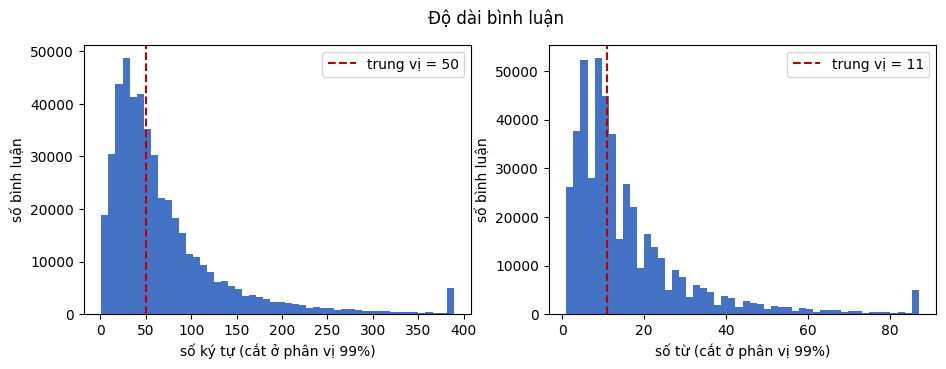

In [20]:
co_chu = raw[~rong]
so_ky_tu = co_chu.str.len()
so_tu = co_chu.str.split().str.len()
display(pd.DataFrame({"số ký tự": so_ky_tu.describe(percentiles=[.1, .25, .5, .75, .9, .99]),
                      "số từ": so_tu.describe(percentiles=[.1, .25, .5, .75, .9, .99])}).round(1))
AUDIT["Độ dài trung vị (ký tự)"] = float(so_ky_tu.median())
AUDIT["Độ dài trung vị (từ)"] = float(so_tu.median())
AUDIT["Bình luận ≤ 2 từ"] = int((so_tu <= 2).sum())
AUDIT["Bình luận > 1.000 ký tự"] = int((so_ky_tu > 1000).sum())
print(f"≤ 2 từ: {(so_tu <= 2).sum():,} | > 1.000 ký tự: {(so_ky_tu > 1000).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, s, ten in [(axes[0], so_ky_tu, "số ký tự"), (axes[1], so_tu, "số từ")]:
    ax.hist(s.clip(upper=s.quantile(.99)), bins=50, color="#4472c4")
    ax.axvline(s.median(), color="#c00000", ls="--", label=f"trung vị = {s.median():.0f}")
    ax.set_xlabel(f"{ten} (cắt ở phân vị 99%)")
    ax.set_ylabel("số bình luận")
    ax.legend()
fig.suptitle("Độ dài bình luận")
plt.show()

### 2.5 Bình luận chỉ có emoji

**Ô code làm gì:**
- Một bình luận "chỉ có emoji" khi mọi ký tự (trừ khoảng trắng) là emoji hoặc biểu tượng: 😂, ❤️, 👍🏻, 👨‍👩‍👧, ★…
- Ký tự nối emoji (ZWJ, `U+FE0F`, màu da) được tính là một phần của emoji.
- Có một chữ cái hay chữ số là không tính.
- In số lượng, các bình luận emoji gặp nhiều nhất, và một số ví dụ.

**Đọc kết quả:** loại này mang cảm xúc nhưng không có khía cạnh, nên không dùng được cho Q2–Q5.

In [21]:
CO_CHU_HOAC_SO = re.compile(r"[^\W_]")   # chữ cái hoặc chữ số, ở mọi ngôn ngữ


def _la_ky_tu_emoji(ch: str) -> bool:
    cp = ord(ch)
    return (unicodedata.category(ch) in ("So", "Sk") or 0x1F000 <= cp <= 0x1FAFF or 0x2600 <= cp <= 0x27BF
            or ch in "‍️⃣" or 0xE0020 <= cp <= 0xE007F)


def chi_co_emoji(s: str) -> bool:
    if CO_CHU_HOAC_SO.search(s):            # có chữ/số thì loại ngay, cho nhanh
        return False
    ky_tu = [ch for ch in s if not ch.isspace()]
    return bool(ky_tu) and all(_la_ky_tu_emoji(ch) for ch in ky_tu)


emoji_only = raw.map(chi_co_emoji)
AUDIT["Bình luận chỉ có emoji"] = int(emoji_only.sum())
print(f"Bình luận chỉ có emoji: {emoji_only.sum():,} ({100 * emoji_only.mean():.2f}%)")
display(raw[emoji_only].value_counts().head(N_SHOW).rename("số lần").to_frame())

Bình luận chỉ có emoji: 2,433 (0.51%)


,số lần
text,
😂,171
😂😂😂,162
❤,111
😂😂,96
👍,90
🤣🤣🤣,80
🤣🤣,71
❤❤❤,60
😂😂😂😂,40


### 2.6 Bình luận chỉ có URL

**Ô code làm gì:**
- Tìm link trong bình luận: `http://…`, `https://…`, `www.…`, hoặc dạng `tên.com`, `tên.vn`, `youtu.be/…`.
- Một bình luận "chỉ có URL" khi bỏ hết link đi thì không còn chữ cái hay chữ số nào.
- Đếm thêm số bình luận **có chứa** URL để so sánh.

**Đọc kết quả:** bình luận chỉ có URL gần như chắc chắn là quảng cáo hoặc spam.

In [22]:
URL_RE = re.compile(r"(?:https?://|www\.)\S+"
                    r"|\b[\w-]+(?:\.[\w-]+)*\.(?:com|vn|net|org|info|io|me|ly|gl|be|co|xyz|shop|top|site|link)\b(?:/\S*)?",
                    re.IGNORECASE)


def chi_co_url(s: str) -> bool:
    if not URL_RE.search(s):
        return False
    return not CO_CHU_HOAC_SO.search(URL_RE.sub(" ", s))


co_url = raw.str.contains(URL_RE)
url_only = raw.map(chi_co_url)
AUDIT["Bình luận có chứa URL"] = int(co_url.sum())
AUDIT["Bình luận chỉ có URL"] = int(url_only.sum())
print(f"Có chứa URL: {co_url.sum():,} ({100 * co_url.mean():.2f}%) | chỉ có URL: {url_only.sum():,}")
display(df.loc[url_only, ["comment_id", "video_id", "model", "text"]].head(N_SHOW))

Có chứa URL: 10,682 (2.25%) | chỉ có URL: 169


,comment_id,video_id,model,text
1111,UghkbwLbCVo0U3gCoAEC.7-H0Z7-SREm7-H0fHIePdB,2I74I1hNfCo,note4,https://www.facebook.com/loc.bui.pq
1646,UgiMDhNbgRViPXgCoAEC,BJ0O7rJQNlM,note5,https://www.facebook.com/thang.quang.904/posts/737898946337537
11693,UgjWZQhoJTAFp3gCoAEC.8S0k4EU54i38S14TaAt4cO,NDgec20haQs,s8,https://uphinhnhanh.com/image/Z2ttL
14753,UgwYztlo-9AKSAuZwYp4AaABAg,TMLX0miCGyM,ip8|note8,https://m.facebook.com/story.php?story_fbid=356017474854625&id=100013391258743
14863,Ugx2aV66qUOhCFlcncd4AaABAg.8Xqm8AERMxt8Y0l8I3nuqo,TMLX0miCGyM,ip8|note8,http://vnreview.vn/tin-tuc-san-pham-moi/-/view_content/content/2283015/iphone-8-plus-galaxy-note8-va-canon-m6-do-camera-xoa-phong-giau-mat
16704,Ugw910X82sF7Ezfvkbt4AaABAg,PYPeo0RfGA8,note8,https://www.youtube.com/watch?v=PYPeo0RfGA8
16714,Ugx2xCy4YZPjPg09pqV4AaABAg.8XwKX5t7jOK8XwM8kuvQKO,PYPeo0RfGA8,note8,https://youtu.be/eVC3tgIgG2I
17090,UgyPmNakgyfytyQNVAR4AaABAg.8Y0Rdxih4kT8Y0ZDGNl8bO,6Ivk92cJQOc,note8,https://youtu.be/0BcpLU-3j3w
18259,Ugzc7rwOZSt_LVX3v3x4AaABAg.8YmPjHERz3C8YoOB_-Q_bP,j4oVP6aoS1A,ip8,https://www.youtube.com/watch?v=My3Y228tA18&t=11s
18291,Ugxe8XIqYqN3O3Sgo3F4AaABAg,j4oVP6aoS1A,ip8,https://www.youtube.com/watch?v=My3Y228tA18&t=11s


### 2.7 Ngôn ngữ

**Ô code làm gì:** đoán ngôn ngữ của từng bình luận bằng luật đơn giản, xét theo thứ tự:

| Nhãn | Khi nào |
|---|---|
| tiếng Việt | Có chữ cái tiếng Việt có dấu (ă, â, đ, ê, ô, ơ, ư, hoặc nguyên âm mang dấu thanh) |
| ngôn ngữ khác | Có chữ viết không phải chữ Latin: Trung, Nhật, Hàn, Thái, Nga, Ả Rập… |
| tiếng Việt không dấu | Chữ Latin không dấu, có nhiều từ tiếng Việt thường gặp ("ko", "dep", "nhung"…) hơn từ tiếng Anh |
| tiếng Anh | Chữ Latin không dấu, có nhiều từ tiếng Anh thường gặp ("the", "is", "this"…) hơn từ tiếng Việt |
| không rõ | Chữ Latin không dấu nhưng không khớp danh sách nào, vd chỉ có tên máy "iphone 15 pro max" |
| không có chữ | Chỉ có emoji, số, ký hiệu, hoặc rỗng |

- Trước khi xét, bình luận được chuẩn NFC, chỉ để nhận dấu cho đúng. Cột `text` không bị sửa.
- Đây là **ước lượng**: chưa dùng mô hình nhận dạng ngôn ngữ. Ô code in ví dụ ngẫu nhiên cho từng nhãn để kiểm tra bằng mắt.

In [23]:
CHU_VIET_CO_DAU = set("ăâđêôơưàáảãạằắẳẵặầấẩẫậèéẻẽẹềếểễệìíỉĩịòóỏõọồốổỗộờớởỡợùúủũụừứửữựỳýỷỹỵ")
TU_VIET = {"ko", "k", "khong", "kh", "la", "cua", "may", "dep", "qua", "nhung", "thi", "co", "cho", "nay", "duoc", "dc",
           "roi", "minh", "toi", "em", "anh", "ae", "gi", "sao", "nhu", "lam", "hon", "van", "chi", "con", "nua", "voi",
           "mua", "dung", "xai", "gia", "tot", "xau", "ngon", "re", "hay", "cung", "vay", "nhi", "nhe", "oi", "ak", "ah",
           "j", "r", "ms", "mik", "mn", "bn", "vs", "mau", "nong", "lag", "ngu", "chup", "sac", "trau", "yeu", "manh"}
TU_ANH = {"the", "is", "are", "and", "of", "it", "this", "that", "you", "my", "for", "with", "not", "but", "have",
          "was", "what", "just", "like", "its", "be", "at", "your", "they", "will", "can", "would", "should", "than",
          "from", "about", "if", "or", "has", "had", "been", "very", "really", "better", "best", "love", "nice",
          "great", "awesome", "please", "thanks", "who", "why", "how", "when", "which", "there", "their"}
TU_CHU = re.compile(r"[^\W\d_]+")


def _la_chu_latin(ch: str) -> bool:
    cp = ord(ch)
    return cp < 0x250 or 0x1E00 <= cp <= 0x1EFF


def doan_ngon_ngu(s: str) -> str:
    s = unicodedata.normalize("NFC", s).lower()
    tu = TU_CHU.findall(s)
    if not tu:
        return "không có chữ"
    if any(ch in CHU_VIET_CO_DAU for ch in s):
        return "tiếng Việt"
    if any(not _la_chu_latin(ch) for t in tu for ch in t):
        return "ngôn ngữ khác"
    viet = sum(t in TU_VIET for t in tu)
    anh = sum(t in TU_ANH for t in tu)
    if viet > anh:
        return "tiếng Việt không dấu"
    if anh > viet:
        return "tiếng Anh"
    return "không rõ"


ngon_ngu = raw.map(doan_ngon_ngu)
bang_nn = ngon_ngu.value_counts().rename("số bình luận").to_frame()
bang_nn["tỷ lệ (%)"] = (100 * bang_nn["số bình luận"] / len(df)).round(2)
display(bang_nn)
for nhan, so in ngon_ngu.value_counts().items():
    AUDIT[f"Ngôn ngữ: {nhan}"] = int(so)

for nhan in bang_nn.index:
    if nhan == "không có chữ":
        continue
    mau = raw[ngon_ngu == nhan]
    print(f"\nVí dụ ngẫu nhiên – {nhan}:")
    display(mau.sample(min(10, len(mau)), random_state=0).to_frame("text"))

,số bình luận,tỷ lệ (%)
text,,
tiếng Việt,445150,93.96
không rõ,14080,2.97
tiếng Việt không dấu,7811,1.65
không có chữ,4555,0.96
tiếng Anh,2000,0.42
ngôn ngữ khác,190,0.04



Ví dụ ngẫu nhiên – tiếng Việt:


,text
69004,cảm ơn bạn đã đánh giá máy này mình rất thích Galaxy 20 Ultra đẳng cấp về mọi mặt hơn iphon 13 là cái bút tuyệt chúc bạn ngày mới vui vẻ
61650,Đù anh duy nghe bài yoru ni kakeru à hehe;))
356007,S26u năm nay chụp vẫn cùi quá. Ko có gì wow
367429,Quay 8k mặt xinh xấu thật 😂😂😂
298963,Tua à? S ko nghe 😂😂
131920,Đáp án: C\nSố may mắn: 7335\nFB: https://www.facebook.com/inhouse.noname.2
212905,Sạc dự phòng đắt nhất thế giới
26618,@heartt-rex7869 Chip tầm gần cao ? Thế có con máy nào ngon hơn con note 10+ vậy bạn ?
199038,"con 13 trông k sang bằng nhưng trông cũng rất nổi bật ấy, cụm cam chà bá thêm cái viền mạ vàng, iphone thì ai cũng biết là iphone rồi nhưng độc lạ là phải xem xét lại ấy ;))"
16716,sony đẹp hơn note 8



Ví dụ ngẫu nhiên – không rõ:


,text
3397,Silver titanium
144471,4663 https://www.facebook.com/phuocacoustic1205
266423,A11 fusion =))
1077,A iphone 6. B note 4
143528,Sdt: 0486 https://www.facebook.com/cuong.hoang.92
56800,iPhone 12 prm
119055,oppo 😂😂
300934,Mi 10t pro 5g
428475,mini = 6.31 inch 🤦‍♂
121292,FUCKING SAMSUNG GALAXY S8!!!😡😡😡



Ví dụ ngẫu nhiên – tiếng Việt không dấu:


,text
131924,Dap an d face book dungmera co share video so may man 4367
92960,lai bat chuoc Ip lam khung nhom titan roi =))
123058,"dep qua,lai sang trong nua"
339609,Xiaomi nen doi ten thanh xiao nhai. Toan la coppy cua nguoi khac.
177225,ngon
140776,tao thay' he dieu hanh ios 11 kieu deo gi ay'. ipad ngay xua thi xem youtube nghe nhac ca ngay. bh thi pin tut nhanh deo' the ta? dc
376441,lam ntn thi luot xem va bl se tang them. dac biet la phan commen se rat nhieu.
2230,minh moi mua hom qua nay
134350,Do la c 3 camera
112024,minh cug vay



Ví dụ ngẫu nhiên – tiếng Anh:


,text
85432,like
276763,Really??
263316,great :v
146772,Wai that
393582,"Please can you tell if audio Is stereo and High volume, not as in 12 which was very low. Also Is there a speaker or of stereo audio comes out from ear capsule? But much more important, did they fix by hardware the proximity sensor like did with 12T Pro or still the same problems like all Xiaomi?"
273622,NiceDay like
346437,Thank you for watching my video bro 🤩
286316,"@mharro88 \nNote 10+ comes with 2 versions, SD 855 in US market and Exynos 9825 in the international market.\n\nThe new SD 855+ which is the equivalent to Exynos 9825 isn't featured in the Note 10+"
446840,"Unfortunately, Vivo did not overcome its problem in dealing with people's faces and did not give good facial details. On the other hand, the Xiaomi camera was better in facial details. So the Vivo phone is designed to photograph objects and nature while photographing people it fails in front of Xiaomi and Samsung. This is a fact in all Vivo phones."
2336,"Oh, like"



Ví dụ ngẫu nhiên – ngôn ngữ khác:


,text
299209,多少
218063,ሰላም ጓደኛዬ ቪዲዮህን አይቼው ነበር የሚገርም ነበር።
437932,​@박지연-h1x m bt db j
284574,حراميه في جميع الأشياء غسالات مكيفات صيانه وسنترالهم وتساعدهم وزارة التجارة
353992,"Оказывается, Самсунг внедрил в данную матрицу, свою новую технологию - Round Diamond Pixel . Плюс внедрение синего фосфоресцентного OLED (Blue PHOLED), который имеет на 20–30% выше энергоэффективность и гораздо больший срок службы. По этому, синий теперь удалось сделать такого же размера, как и другие светодиоды. Плюс Samsung внедрила технологию CoE (Color Filter on Encapsulation), которая позволила полностью убрать пластиковый поляризатор. И именно по этому, пришлось использовать круглую форму субпикселей, так как без поляризатора свет от классических ""ромбовидных"" пикселей, начинает слишком сильно дифрагировать (рассеиваться) на краях. \r\nНу и конечно, Privacy Display - технология Flex Magic Pixel (FMP), которая разделяет экран на два типа пикселей: Wide Pixels (широкоугольные) и Narrow Pixels (узконаправленные).\r\nКороче, с технической точки зрения, это самый технологичный и крутой дисплей, который когда-либо устанавливали в смартфоны. Правда, качество изображения, пока немного страдает. Думаю в S27U, исправят все недостатки, ведь это всё таки самая первая генерация такой матрицы."
176161,คุณสร้างเครือข่าย 5G ที่ครอบคลุมใด้เมื่อไหร แอฟเปิ้ลสโตร์ ก็คงจะเกิดขึ้นในเวียดนาม อย่างแน่นอน 👍👍
51672,ㅣㅣㅣ
354008,"@WuSu-u3x В матрице S26U, синий диод такого же размера как и зеленый и красный. Посмотрите видео. Так что теперь действительно, высокий риск выгорания синих субпикселей ."
399987,RMB6999相当于2300万越南盾，这个价格对普通中国人来说是偏贵的! 普通中国人一个多月工资😂
17809,Linh 朴芝妍 😘


### 2.8 Thời gian: trải dài bao lâu, ngày nào tăng đột biến

**Ô code làm gì:**
- In bình luận sớm nhất, muộn nhất, khoảng thời gian trải dài. Giờ đổi sang giờ Việt Nam.
- Đếm số bình luận mỗi ngày và vẽ biểu đồ theo thời gian.
- Đánh dấu **ngày đột biến**: ngày có số bình luận ≥ `HE_SO_DOT_BIEN` lần trung vị của 7 ngày quanh nó, và ≥ `TOI_THIEU_NGAY` bình luận (để bỏ qua ngày lặng).
- Với mỗi ngày đột biến, in video và máy đóng góp nhiều nhất hôm đó, để biết vì sao tăng.

**Đọc kết quả:**
- Crawler chỉ lấy bình luận trong 4 tuần sau ngày ra mắt của từng máy. Vì vậy biểu đồ thành từng cụm quanh các đợt ra mắt, giữa các cụm có khoảng trống. Đó là do cách crawl, không phải người xem bỏ đi.
- Ngày đột biến thường do một video "nổ".

Sớm nhất: 2014-04-11 00:22:32+07:00 | muộn nhất: 2026-10-20 18:52:16+07:00 | trải dài 4,575 ngày
Bình luận không đọc được thời điểm đăng: 0


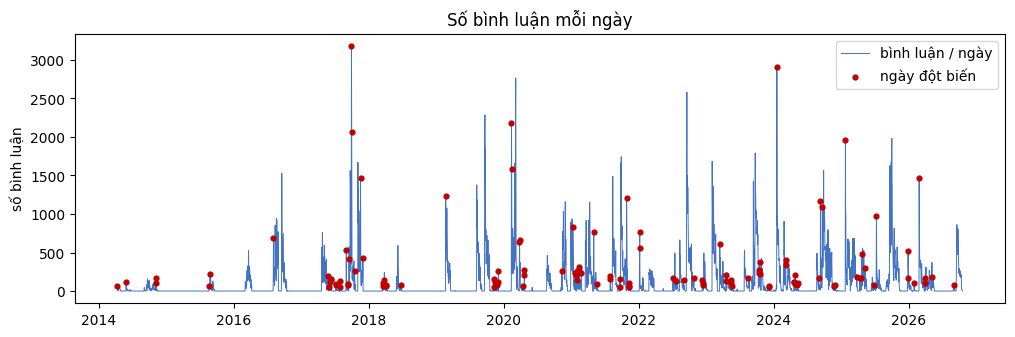

Ngày đột biến: 116


,ngày,số bình luận,trung vị 7 ngày,máy nhiều nhất,video nhiều nhất,bình luận của video đó,tiêu đề
0,2017-09-29,3180,553.0,note8,t1vCy2uQWJw,2771,NHẬN GALAXY J7 PRO MIỄN PHÍ khi trả lời câu hỏi về NOTE 8 !!
1,2024-01-18,2911,848.0,s24u,6r7G_eH9ckU,365,"Ấn tượng thực tế với Galaxy S24 Ultra: đẹp, rất đẹp, test nhnah tính năng AI cho anh em coi"
2,2020-02-12,2181,238.0,s20ultra,71lpO1asWcQ,860,"Đánh giá nhanh GALAXY S20 ULTRA 108MP, 5000mAh"
3,2017-09-30,2066,553.0,note8,t1vCy2uQWJw,1805,NHẬN GALAXY J7 PRO MIỄN PHÍ khi trả lời câu hỏi về NOTE 8 !!
4,2025-01-23,1956,419.0,s25u,i8UwleCkdSg,376,"Mở hộp Galaxy S25 Ultra: NÂNG CẤP NHỮNG GÌ, CÓ ĐÁNG KHÔNG?"
5,2020-02-13,1578,238.0,s20ultra,4ueUUb3dWQg,816,So sánh Galaxy S20 Ultra & iPhone 11 Pro Max
6,2026-02-26,1473,412.0,s26u,TzY6m1rOgjU,523,"Trên Tay Bộ 3 Samsung Galaxy S26 Ultra, Galaxy S26 và S26+: Màn Chống Nhìn Trộm Độc Quyền, Sạc 60W"
7,2017-11-17,1461,285.0,ipx,FbKYwezqjHU,1330,SHOCK ! TẶNG iPhone X trị giá 30 triệu MIỄN PHÍ nhân dịp 900K subscribe từ iFind
8,2019-02-21,1228,384.0,s10plus,P-m1zHT2eDc,458,Trên tay Samsung Galaxy S10+
9,2021-10-27,1205,367.0,pixel6pro,zDpEpPdKfN4,342,So sánh Pixel 6 Pro và iPhone 13 Pro Max: Google làm được gì khi so với Apple?


In [24]:
HE_SO_DOT_BIEN = 3      # gấp mấy lần trung vị 7 ngày quanh đó thì tính là đột biến
TOI_THIEU_NGAY = 50     # ngày ít hơn số này thì không xét

t = thoi_gian.dropna()
print(f"Sớm nhất: {t.min()} | muộn nhất: {t.max()} | trải dài {(t.max() - t.min()).days:,} ngày")
print(f"Bình luận không đọc được thời điểm đăng: {thoi_gian.isna().sum():,}")
AUDIT["Ngày sớm nhất"] = str(t.min().date())
AUDIT["Ngày muộn nhất"] = str(t.max().date())

theo_ngay = t.dt.floor("D").value_counts().sort_index()
theo_ngay = theo_ngay.asfreq("D", fill_value=0)   # thêm cả ngày không có bình luận (= 0)
nen = theo_ngay.rolling(7, center=True, min_periods=1).median()
dot_bien = theo_ngay[(theo_ngay >= HE_SO_DOT_BIEN * nen.clip(lower=1)) & (theo_ngay >= TOI_THIEU_NGAY)]
AUDIT["Số ngày đột biến"] = len(dot_bien)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(theo_ngay.index, theo_ngay.values, lw=0.7, color="#4472c4", label="bình luận / ngày")
ax.scatter(dot_bien.index, dot_bien.values, color="#c00000", s=12, zorder=3, label="ngày đột biến")
ax.set_ylabel("số bình luận")
ax.set_title("Số bình luận mỗi ngày")
ax.legend()
plt.show()

ngay = thoi_gian.dt.floor("D")
chi_tiet = []
for d, so in dot_bien.sort_values(ascending=False).items():
    hom_do = df[ngay == d]
    v = hom_do["video_id"].value_counts()
    chi_tiet.append({"ngày": d.date(), "số bình luận": so, "trung vị 7 ngày": nen[d],
                     "máy nhiều nhất": hom_do["model"].value_counts().index[0],
                     "video nhiều nhất": v.index[0], "bình luận của video đó": v.iloc[0],
                     "tiêu đề": vd["title"].get(v.index[0], "") if vd is not None else ""})
print(f"Ngày đột biến: {len(dot_bien):,}")
display(pd.DataFrame(chi_tiet).head(N_SHOW))

### 2.9 Nhiều bình luận giống nhau đăng dồn trong thời gian ngắn

**Để làm gì:** nhiều bình luận cùng nội dung đăng dồn trong vài phút là dấu hiệu bot, seeding, hoặc spam hàng loạt.

**Ô code làm gì:**
- So nội dung sau khi bỏ khác biệt hoa/thường và khoảng trắng.
- Chỉ xét nội dung dài ≥ `TOI_THIEU_KY_TU` ký tự, để bỏ qua câu ngắn tự nhiên như "hay".
- Một nhóm bị đánh dấu khi có ≥ `TOI_THIEU_LAN` bình luận cùng nội dung nằm trong một khung `CUA_SO`.
- In các nhóm đó, kèm:
  - số lần đăng trong khung dày nhất;
  - thời điểm bắt đầu khung;
  - số video, số người đăng.

**Đọc kết quả:**
- Nhiều người, nhiều video, cùng nội dung, trong vài phút: khả năng cao là chiến dịch.
- Một người đăng lặp: spam cá nhân.

In [25]:
CUA_SO = pd.Timedelta(minutes=10)
TOI_THIEU_LAN = 3
TOI_THIEU_KY_TU = 10

khoa = raw.str.lower().str.split().str.join(" ")   # bỏ khác biệt hoa/thường và khoảng trắng
giay = (thoi_gian - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()
xet = (khoa.str.len() >= TOI_THIEU_KY_TU) & khoa.duplicated(keep=False) & giay.notna()
d = pd.DataFrame({"khoa": khoa[xet], "giay": giay[xet], "video_id": df.loc[xet, "video_id"],
                  "author_hash": df.loc[xet, "author_hash"]})

nhom = []
w = CUA_SO.total_seconds()
for k, g in d.groupby("khoa", sort=False):
    if len(g) < TOI_THIEU_LAN:
        continue
    g = g.sort_values("giay")
    s = g["giay"].to_numpy()
    dem = np.searchsorted(s, s + w, side="right") - np.arange(len(s))   # số bình luận trong khung bắt đầu ở mỗi lần đăng
    i = int(dem.argmax())
    if dem[i] >= TOI_THIEU_LAN:
        khung = g.iloc[i:i + dem[i]]
        nhom.append({"nội dung": k, "tổng số lần": len(g), "số lần trong khung": int(dem[i]),
                     "bắt đầu": pd.Timestamp(s[i], unit="s", tz="UTC").tz_convert("Asia/Ho_Chi_Minh"),
                     "số video": khung["video_id"].nunique(), "số người": khung["author_hash"].nunique()})

dang_don = pd.DataFrame(nhom)
if len(dang_don):
    dang_don = dang_don.sort_values(["số lần trong khung", "tổng số lần"], ascending=False)
AUDIT["Nhóm nội dung đăng dồn"] = len(dang_don)
AUDIT["Bình luận trong các khung đăng dồn"] = int(dang_don["số lần trong khung"].sum()) if len(dang_don) else 0
print(f"Nhóm nội dung có ≥ {TOI_THIEU_LAN} lần đăng trong {CUA_SO}: {len(dang_don):,}")
display(dang_don.head(N_SHOW))

Nhóm nội dung có ≥ 3 lần đăng trong 0 days 00:10:00: 308


,nội dung,tổng số lần,số lần trong khung,bắt đầu,số video,số người
117,bao nhiêu lâu bán được 1 tỷ gói mè,81,53,2021-10-14 20:32:56+07:00,1,2
188,mình nhận đáp án ạ!,154,48,2019-02-28 15:19:13+07:00,1,1
189,chúc bạn may mắn nhé!,117,27,2019-03-04 16:08:05+07:00,1,1
283,"cần bán xiaomi 14t pro bản 12/512gb chính hãng, nguyên seal, tặng kèm sạc chính hãng 120w. giá 13x (x nhỏ).",23,19,2024-10-18 21:08:47+07:00,5,2
99,"chào bạn, hiện tại pineng pn-888 có giá bán 599.000đ, bạn có thể xem chi tiết sản phẩm tại đây: https://goo.gl/hehngp. trân trọng!",18,18,2017-11-10 10:09:03+07:00,1,1
134,thằng nguyên bố láo. sẽ bị container kál na/t ó.c,18,18,2023-09-25 19:39:23+07:00,1,1
205,anh ơi tầm giá 6 triệu rưỡi mua diện thoại nào là tốt nhất ạ,16,16,2021-08-29 10:44:06+07:00,1,1
279,"mua 14t qua thế giới di động 18b trần phú - hà đông ae nhé đang giảm 1,5tr chỉ từ 11.490k vẫn tặng kèm sạc áp dụng cho tới ngày 18/10/2024",22,13,2024-10-12 23:04:21+07:00,4,3
245,"chào bạn. galaxy s20 series có giá bán lẻ đề nghị từ 21.490.000vnđ. đặt trước ngay, rước quà sành điệu: bao da clear view hoặc tai nghe galaxy buds+, cùng các ưu đãi độc quyền giá trị khác như dịch vụ phòng chờ thương gia và chương trình trả góp 0% lên đến 24 tháng. khám phá ngay tại: http://bit.ly/galaxys20-feb20",14,13,2020-02-25 11:53:17+07:00,1,1
56,"mọi người có thể tư vấn cho em nên chọn android snapdragon 8 gen 2 hay iphone a16 không. nhu cầu của em là làm kênh youtube về game và quay màn hình những game ví dụ liên minh tốc chiến, gta sa để đăng. thì mình nên chọn android hay iphone? iphone thì sạc chậm, android thì ram nhiều, quá khó chọn. còn ví dụ android thì cũng không biết nên chọn gaming phone hay xiaomi 13 pro hay s23 ultra.",10,10,2023-02-20 20:33:18+07:00,4,1


### Tổng hợp Level 0

**Đọc kết quả:** các con số chính của mục 2.1–2.9 trên một bảng, để chép vào báo cáo hay so giữa các lần crawl.

In [26]:
display(pd.Series(AUDIT, name="giá trị").to_frame())

,giá trị
Số video có bình luận,4682
Video có < 10 bình luận,1027
Bình luận rỗng,42
Trùng comment_id,0
Bình luận có nội dung trùng với bình luận khác,19510
Bình luận một người đăng lại cùng nội dung,7584
Độ dài trung vị (ký tự),50.0
Độ dài trung vị (từ),11.0
Bình luận ≤ 2 từ,26184
Bình luận > 1.000 ký tự,328


## 3. Level 1 – Technical Cleaning

**Để làm gì:** sửa các lỗi **kỹ thuật** trong chữ: lỗi do cách máy lưu và truyền văn bản, không phải do người viết. Level 1 **không đổi nghĩa** bình luận:
- không đổi chữ hoa/thường;
- không sửa teencode, chính tả;
- không bỏ emoji;
- không lọc spam.

Các việc đó thuộc level sau.

| Bước | Lỗi | Cách xử lý |
|---|---|---|
| B1 | Comment null | Đánh dấu bình luận trống (null, rỗng, chỉ có khoảng trắng) |
| B2 | HTML entities | `&#39;` → `'`, `&amp;` → `&`, `&quot;` → `"` … |
| B3 | Ký tự điều khiển không cần thiết | Bỏ ký tự điều khiển và ký tự vô hình (zero-width space, BOM, word joiner, NUL…) |
| B4 | Unicode không thống nhất | Chuẩn NFC: chữ có dấu ghép từ nhiều ký tự gộp về một ký tự dựng sẵn |
| B5 | Xuống dòng bất thường | `\r\n`, `\r` và các ký tự xuống dòng lạ → `\n`; nhiều dòng trống liền nhau → một lần xuống dòng |
| B6 | Khoảng trắng dư | Tab, khoảng trắng lạ (NBSP…) → dấu cách; nhiều dấu cách → một; bỏ khoảng trắng đầu/cuối |
| B7 | Comment null sau làm sạch | Đánh dấu bình luận chỉ chứa ký tự vô hình, sau B3–B6 thành rỗng |

**Vì sao theo thứ tự này:**
- B2 chạy trước vì giải mã entity có thể sinh ra ký tự điều khiển hay khoảng trắng lạ (vd `&nbsp;`), các bước sau sẽ dọn.
- B3 bỏ ký tự vô hình trước B4, vì ký tự vô hình chen giữa chữ và dấu làm NFC không gộp được.
- B5 chạy trước B6, để dòng chỉ có dấu cách cũng được tính là dòng trống.

**Mỗi ô code bên dưới:** định nghĩa hàm sửa một loại lỗi, áp lên toàn bộ bình luận, rồi in:
- số bình luận bị sửa;
- tối đa `N_SHOW` ví dụ trước → sau.

### Công cụ hiển thị

**Ô code làm gì:** tạo 2 hàm dùng cho mọi bước:
- `lo_ra(s)`: hiện ký tự vô hình để nhìn thấy được. Xuống dòng hiện là `⏎`, tab là `⇥`; ký tự vô hình khác hiện mã, vd `⟨U+200B⟩`; dấu cách thừa (từ 2 cái liền nhau, hoặc ở đầu/cuối) hiện là `·`.
- `bao_cao(...)`: đếm bình luận bị một bước sửa, in ví dụ trước → sau, ghi vào bảng tổng kết.

Cột "độ dài trước → sau" giúp thấy thay đổi không nhìn được bằng mắt. Vd ở B4, `à` ghép từ 2 ký tự thành 1 ký tự, nên độ dài giảm.

In [27]:
KY_HIEU = {"\n": "⏎", "\t": "⇥", "\r": "␍"}
DAU_CACH_THUA = re.compile(r" {2,}|^ +| +$", re.M)


def lo_ra(s) -> str:
    """Trả chuỗi để hiển thị, trong đó ký tự vô hình được thay bằng ký hiệu nhìn thấy được."""
    if not isinstance(s, str):
        return "<null>"
    out = []
    for ch in s:
        if ch in KY_HIEU:
            out.append(KY_HIEU[ch])
        elif ch != " " and unicodedata.category(ch) in ("Cc", "Cf", "Cs", "Zs", "Zl", "Zp"):
            out.append(f"⟨U+{ord(ch):04X}⟩")
        else:
            out.append(ch)
    return DAU_CACH_THUA.sub(lambda m: "·" * len(m.group()), "".join(out))


BAO_CAO = []   # mỗi bước thêm một dòng; in thành bảng tổng kết ở cuối mục 3


def bao_cao(ten: str, truoc: pd.Series, sau: pd.Series, n: int = N_SHOW) -> None:
    """In số bình luận mà một bước đã sửa và tối đa n ví dụ trước → sau."""
    doi = truoc != sau
    so = int(doi.sum())
    BAO_CAO.append({"bước": ten, "số bình luận bị sửa": so, "tỷ lệ (%)": round(100 * so / len(truoc), 3)})
    print(f"{ten}: sửa {so:,} / {len(truoc):,} bình luận ({100 * so / len(truoc):.3f}%)")
    if so == 0:
        return
    idx = doi[doi].index[:n]
    display(pd.DataFrame({
        "comment_id": df.loc[idx, "comment_id"],
        "trước": truoc[idx].map(lo_ra),
        "sau": sau[idx].map(lo_ra),
        "độ dài trước → sau": truoc[idx].str.len().astype(str) + " → " + sau[idx].str.len().astype(str),
    }))

### B1. Comment null

**Để làm gì:** tìm bình luận không có nội dung: `text` là null, là chuỗi rỗng, hoặc chỉ có khoảng trắng. Không có chữ thì không phân tích được.

**Ô code làm gì:**
- Đánh dấu các bình luận này ở cột `la_null`.
- Đổi null thành chuỗi rỗng để các bước sau chạy được trên mọi dòng.
- In danh sách bình luận null.

Bình luận null **không bị xóa** khỏi bảng, chỉ được đánh dấu. Bỏ hay giữ là việc của bước sau.

In [28]:
goc = df["text"]
la_null = goc.isna() | (goc.fillna("").astype(str).str.strip() == "")
df["la_null"] = la_null
print(f"Comment null: {la_null.sum():,} / {len(df):,}")
display(df.loc[la_null, ["comment_id", "video_id", "model"]].assign(text=goc[la_null].map(lo_ra)).head(N_SHOW))

text = goc.fillna("").astype(str)   # chuỗi đang làm sạch, đi qua lần lượt B2 → B6

Comment null: 42 / 473,786


,comment_id,video_id,model,text
34,UgjbOdscgJD2yHgCoAEC,9SmOJHZTkC4,ip6,
58,UgiIqSCXBt5YdXgCoAEC,9SmOJHZTkC4,ip6,
1073,UgjxaDGwkIYC-3gCoAEC,2I74I1hNfCo,note4,
1239,UghrV9A4qnP0FngCoAEC,2I74I1hNfCo,note4,
1253,Ughu11aZQN_2SHgCoAEC,2I74I1hNfCo,note4,
16560,UgjZkwtATSIqRHgCoAEC,PYPeo0RfGA8,note8,
76115,UgzAYGX2_TjsrTBsR-R4AaABAg.9g71aopSA5R9g75ZK5M2bO,uh3LzLnGJM0,ip14prm,
84805,UgwaUrKazJb56U-szsB4AaABAg,wLmIfDX2YJo,s23u,
91564,UgxM7m_4IhnA2B76ZaZ4AaABAg,GuwxQLtkbdY,xiaomi13u,
109810,UghOblKNP43AtXgCoAEC,x0ecYuH2dwk,s5,


### B2. HTML entities

**Để làm gì:** HTML entity là cách viết ký tự đặc biệt trong trang web: `&#39;` là `'`, `&amp;` là `&`, `&quot;` là `"`, `&lt;` là `<`. Bình luận YouTube đôi khi còn sót dạng này. Không đổi lại thì cùng một câu có hai cách viết, và `&#39;` bị coi như chữ.

**Ô code làm gì:**
- Chỉ đổi entity viết đúng dạng `&tên;`, `&#số;`, `&#xHEX;` (phải có dấu `;`), để không đụng vào chữ thường như "AT&T".
- Lặp tối đa 3 lần cho chuỗi bị mã hóa chồng, vd `&amp;#39;` → `&#39;` → `'`.

In [29]:
ENTITY_RE = re.compile(r"&(?:#\d{1,7}|#[xX][0-9a-fA-F]{1,6}|[A-Za-z][A-Za-z0-9]{1,31});")


def giai_ma_html(s: str) -> str:
    """Đổi HTML entity về ký tự thật; lặp tới khi không còn gì để đổi (tối đa 3 lần)."""
    for _ in range(3):
        moi = ENTITY_RE.sub(lambda m: html.unescape(m.group(0)), s)
        if moi == s:
            break
        s = moi
    return s


truoc, text = text, text.map(giai_ma_html)
bao_cao("B2. HTML entities", truoc, text)

B2. HTML entities: sửa 6 / 473,786 bình luận (0.001%)


,comment_id,trước,sau,độ dài trước → sau
2552,Ugi2PpMdkYJSN3gCoAEC.8BZyfU_MOs68BamvhsJGDM,"+Rohan Srivastava +Rohan Srivastava No man, I don&#39;t speak a word of Thai (is that the language?) but I definitely recognize the higher 3D score on antutu on the right (snapdragon) and on the left there is a lower single core geekbench score, but higher multicore (exynos). I have no clue what he says but I&#39;m absolutely sure the numbers on the left match the Exynos 8890 and on the right Snapdragon 820. In the thumbnail of the video it even shows Exynos 8890 on the left vs snap 820 on the right","+Rohan Srivastava +Rohan Srivastava No man, I don't speak a word of Thai (is that the language?) but I definitely recognize the higher 3D score on antutu on the right (snapdragon) and on the left there is a lower single core geekbench score, but higher multicore (exynos). I have no clue what he says but I'm absolutely sure the numbers on the left match the Exynos 8890 and on the right Snapdragon 820. In the thumbnail of the video it even shows Exynos 8890 on the left vs snap 820 on the right",504 → 496
2787,UggkYwI1M7xHengCoAEC.8BWWZ4UFZnh8BX2wXjAQo9,+tho minh GPU của exynos n&#243; tương th&#237;ch game k&#233;m hơn snapdr chứ k phải yếu đâu,+tho minh GPU của exynos nó tương thích game kém hơn snapdr chứ k phải yếu đâu,93 → 78
5688,Ugheua0v5EVFkXgCoAEC.8IulDHC7Kwy8IvTSDEm_5c,&#253; m&#236;nh l&#224; chip ip mạnh m&#224; chạy android cũng thua th&#244;i ! v&#227;i chưởng mấy chế qu&#225; :)),ý mình là chip ip mạnh mà chạy android cũng thua thôi ! vãi chưởng mấy chế quá :)),117 → 82
5716,UgixH0n-7ubPhXgCoAEC.8IujtjVCVPH8IunP3-tAci,"h&#236;nh như chưa c&#243; b&#224;i ss hai con n&#224;y hiệu năng như n&#224;o n&#234;n kh&#244;ng thể n&#243;i thế được, c&#242;n nếu bạn nghĩ ios chạy nhanh hơn android th&#236; con a10 mạnh hơn con 820 th&#236; m&#236;nh cũng chịu.","hình như chưa có bài ss hai con này hiệu năng như nào nên không thể nói thế được, còn nếu bạn nghĩ ios chạy nhanh hơn android thì con a10 mạnh hơn con 820 thì mình cũng chịu.",234 → 174
250493,UgjSiFOsAmoeV3gCoAEC.8H5FFMBMy-W8H8Z0KNl7rp,"Sao bạn ko chờ Android 6 l&#234;n mượt lắm, ram tốt hơn nữa","Sao bạn ko chờ Android 6 lên mượt lắm, ram tốt hơn nữa",59 → 54
251616,UghaUGNj3oLLKXgCoAEC.8H9ox8NGC9O8HBuwxSp_M2,"Mũi t&#234;n sai chiều, IR --> Mống mắt --> Camera IR, chứ vẽ IR --> Mống mắt <-- Camera IR n&#243;i chung l&#224; ko đ&#250;ng nguy&#234;n tắc đường đi của &#225;nh s&#225;ng lắm. Hehe","Mũi tên sai chiều, IR --> Mống mắt --> Camera IR, chứ vẽ IR --> Mống mắt <-- Camera IR nói chung là ko đúng nguyên tắc đường đi của ánh sáng lắm. Hehe",185 → 150


### B3. Ký tự điều khiển không cần thiết

**Để làm gì:** có những ký tự không hiện ra màn hình nhưng vẫn nằm trong chuỗi. Chúng làm hai câu nhìn giống hệt nhau mà máy coi là khác nhau, và có thể làm vỡ việc tách từ. Ví dụ:
- zero-width space `U+200B`: hay dính sau tên người được nhắc;
- word joiner `U+2060`;
- BOM `U+FEFF`;
- ký tự đổi chiều chữ `U+200E`;
- ký tự điều khiển cũ như NUL `U+0000`, backspace `U+0008`, DEL `U+007F`.

**Ô code làm gì:**
- Bỏ mọi ký tự thuộc nhóm Unicode `Cc` (điều khiển) và `Cf` (định dạng, vô hình), cùng các mảnh surrogate lỗi.
- **Giữ lại**, vì là một phần của nội dung:
  - xuống dòng, tab, `\r`: để B5, B6 xử lý;
  - zero-width joiner `U+200D` khi nằm **giữa hai emoji**: nó ghép emoji, vd 👨‍👩‍👧 hay 🏳️‍🌈. ZWJ đứng lẻ hoặc cạnh chữ thì vẫn bỏ;
  - ký tự tag `U+E0020–E007F`: thuộc emoji cờ như 🏴󠁧󠁢󠁥󠁮󠁧󠁿.
- Ký tự riêng (Private Use, vd logo Apple `U+F8FF`) và emoji mới mà Python chưa biết **không** bị bỏ: chúng không phải ký tự điều khiển.

In [30]:
GIU_CHO_BUOC_SAU = {"\t", "\n", "\r", "\x0b", "\x0c", "\x85"}   # khoảng trắng và xuống dòng: B5, B6 xử lý
ZWJ = "‍"


def _can_bo(cp: int) -> bool:
    ch = chr(cp)
    if ch in GIU_CHO_BUOC_SAU or ch == ZWJ or 0xE0020 <= cp <= 0xE007F:
        return False
    return unicodedata.category(ch) in ("Cc", "Cf", "Cs")


def _tao_regex_ky_tu_bo() -> re.Pattern:
    """Gom mọi mã cần bỏ thành các khoảng liên tiếp, tạo một regex [ ... ] (chạy một lần, ~1 giây)."""
    khoang = []
    for cp in range(sys.maxunicode + 1):
        if _can_bo(cp):
            if khoang and cp == khoang[-1][1] + 1:
                khoang[-1][1] = cp
            else:
                khoang.append([cp, cp])
    ma = lambda cp: f"\\U{cp:08X}"
    return re.compile("[" + "".join(ma(a) if a == b else f"{ma(a)}-{ma(b)}" for a, b in khoang) + "]")


KY_TU_BO_RE = _tao_regex_ky_tu_bo()


def _la_emoji(ch: str) -> bool:
    """Ký tự có thể đứng hai bên ZWJ trong một emoji ghép: biểu tượng (So), màu da (Sk), emoji mới chưa có tên (Cn), U+FE0F."""
    return unicodedata.category(ch) in ("So", "Sk", "Cn") or ch == "️"


def _xu_ly_zwj(s: str) -> str:
    """Giữ ZWJ nằm giữa hai emoji, bỏ ZWJ ở mọi chỗ khác."""
    def thay(m):
        i = m.start()
        truoc_ = s[i - 1] if i > 0 else ""
        sau_ = s[i + 1] if i + 1 < len(s) else ""
        return ZWJ if truoc_ and sau_ and _la_emoji(truoc_) and _la_emoji(sau_) else ""
    return re.sub(ZWJ, thay, s)


def bo_ky_tu_dieu_khien(s: str) -> str:
    """Bỏ ký tự điều khiển và ký tự vô hình (trừ những ký tự giữ lại ở trên)."""
    s = KY_TU_BO_RE.sub("", s)
    if ZWJ in s:
        s = _xu_ly_zwj(s)
    return s


truoc, text = text, text.map(bo_ky_tu_dieu_khien)
bao_cao("B3. Ký tự điều khiển, ký tự vô hình", truoc, text)

B3. Ký tự điều khiển, ký tự vô hình: sửa 13,444 / 473,786 bình luận (2.838%)


,comment_id,trước,sau,độ dài trước → sau
1205,Ugivf8owlRRvtHgCoAEC,"⟨U+00A0⟩⏎⏎Số điện thoại 0914529171⏎Link facebook cá nhân:www.facebook.com/tuankiet.le.5076⏎Dự đoán máy⏎Máy A: Iphone 6⏎Máy B: Samsung Galaxy Note 4⏎Đánh giá⏎+Máy A cho hình ảnh thực nhưng chụp và quay video thiếu sáng không được tốt lắm. Quay video bắt nét nhanh.⏎Máy B Chụp hình sắc nét và màu sắc ""nịnh"" mắt, chụp ảnh và quay video trong điều kiện thiếu sáng cực kì tốt ^^⏎Em vote máy B (Note 4) tốt hơn ⏎Số may mắn: 15 :)⟨U+FEFF⟩⏎⏎","⟨U+00A0⟩⏎⏎Số điện thoại 0914529171⏎Link facebook cá nhân:www.facebook.com/tuankiet.le.5076⏎Dự đoán máy⏎Máy A: Iphone 6⏎Máy B: Samsung Galaxy Note 4⏎Đánh giá⏎+Máy A cho hình ảnh thực nhưng chụp và quay video thiếu sáng không được tốt lắm. Quay video bắt nét nhanh.⏎Máy B Chụp hình sắc nét và màu sắc ""nịnh"" mắt, chụp ảnh và quay video trong điều kiện thiếu sáng cực kì tốt ^^⏎Em vote máy B (Note 4) tốt hơn ⏎Số may mắn: 15 :)⏎⏎",420 → 419
2213,UgifYJ2jqGuHrngCoAEC.8423atvBA8w7-HBJ9Mf00T,Nhan Huynh⟨U+200B⟩ có mỗi 2 thú vui là đt và cf =)),Nhan Huynh có mỗi 2 thú vui là đt và cf =)),44 → 43
2537,UgiWETWVT5EHuXgCoAEC.8BdAC_J35BY8Bm_k2ciknJ,how about the camera?i read some review that the snapdragon model has sony sensor and the exynos has a isocell !⟨U+FEFF⟩,how about the camera?i read some review that the snapdragon model has sony sensor and the exynos has a isocell !,113 → 112
2548,UgiEzKiSRmI7FXgCoAEC.8BcI5wZGPn58BpVB4v0uSU,Nguyên Hoang⟨U+200B⟩ that means im lucky becouse i got the exynos version a little confuse becouse the camera sensor in my s7 edge is isocel a samsung lens not a sony exmor rs sensor,Nguyên Hoang that means im lucky becouse i got the exynos version a little confuse becouse the camera sensor in my s7 edge is isocel a samsung lens not a sony exmor rs sensor,175 → 174
19105,Ugym2E-QVNx9p185O2J4AaABAg,⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩,,256 → 0
26338,UgzEDlJSjmKAP8znACF4AaABAg.9-8E_H3y4er9-9-D0EmRDA,⟨U+200B⟩@ponofficial669 Androi thuần GOOGL

### B4. Unicode không thống nhất

**Để làm gì:** một chữ tiếng Việt có dấu có thể được lưu theo hai cách, nhìn giống hệt nhau:
- **dựng sẵn:** `à` là 1 ký tự (`U+00E0`);
- **tổ hợp:** `a` + dấu huyền rời (`U+0300`), tức 2 ký tự.

Máy coi hai cách là hai chữ khác nhau. Không chuẩn hóa thì tìm "màn hình" sẽ trượt những bình luận gõ kiểu tổ hợp, và đếm từ bị tách đôi.

**Ô code làm gì:** chuẩn hóa **NFC**, đưa mọi chữ về dạng dựng sẵn. NFC không đổi nội dung, chỉ đổi cách lưu.

**Không làm ở đây:**
- **NFKC:** nó còn đổi cả nội dung như `①` → `1`, chữ kiểu cách `𝐀` → `A`, `…` → `...`.
- **Thống nhất kiểu bỏ dấu cũ/mới** (`hoà`/`hòa`, `thuý`/`thúy`): đây là chuẩn hóa ngôn ngữ, không phải lỗi kỹ thuật.

In [31]:
def chuan_unicode(s: str) -> str:
    """Đưa chữ có dấu về dạng dựng sẵn (NFC)."""
    return unicodedata.normalize("NFC", s)


truoc, text = text, text.map(chuan_unicode)
bao_cao("B4. Unicode NFC", truoc, text)

B4. Unicode NFC: sửa 7,506 / 473,786 bình luận (1.584%)


,comment_id,trước,sau,độ dài trước → sau
32,Ugj7BfLUSfQ4n3gCoAEC,Nhìn anh xài ma so hư nút nguồn·,Nhìn anh xài ma so hư nút nguồn·,35 → 32
47,UghT5JbOEcU4tngCoAEC,Trước đây cũng là ifan nhưng h thấy hơi thất vọng về apple,Trước đây cũng là ifan nhưng h thấy hơi thất vọng về apple,65 → 58
48,UggOYROxjD0o23gCoAEC,Trước đây cũng là ifan nhưng h thấy hơi thất vọng về apple,Trước đây cũng là ifan nhưng h thấy hơi thất vọng về apple,65 → 58
73,UgiKr2SLhbCU_ngCoAEC,"Có cái điện thoại mà suốt ngày cãi nhau . Tùy theo nhu cầu sử dụng mà mua , về sau này 6 và 6+ có phân phối chính hãng ở VN rồi giá sẽ giống 5-5s trước thôi . Bây giờ toàn thương nhân , cầm tay nắm chân về thì người ta hét giá cao là đươg nhiên , giá của hàng xtay là dựa vào thị trường mà , nó được quan tâm , săn đón thì nó vậy sao cứ phải thắc mắc . Còn mấy bạn thích vơ đũa cả nắm nếu ko nói chuyện khách quan hơn thì chẳng ai phục được ý kiến của các bạn đâu . Một câu chuyện nó giống như một hình đa diện vậy , hãy nhìn vào tất cả các mặt .","Có cái điện thoại mà suốt ngày cãi nhau . Tùy theo nhu cầu sử dụng mà mua , về sau này 6 và 6+ có phân phối chính hãng ở VN rồi giá sẽ giống 5-5s trước thôi . Bây giờ toàn thương nhân , cầm tay nắm chân về thì người ta hét giá cao là đươg nhiên , giá của hàng xtay là dựa vào thị trường mà , nó được quan tâm , săn đón thì nó vậy sao cứ phải thắc mắc . Còn mấy bạn thích vơ đũa cả nắm nếu ko nói chuyện khách quan hơn thì chẳng ai phục được ý kiến của các bạn đâu . Một câu chuyện nó giống như một hình đa diện vậy , hãy nhìn vào tất cả các mặt .",636 → 546
84,UgjikjH1dlNY9ngCoAEC,"ở vn , cầm iphone là nhà ta giàu :))","ở vn , cầm iphone là nhà ta giàu :))",41 → 36
88,UggrWrA48JjPxXgCoAEC,"Chỉ cần 1 miếng dán trùng với màu nhôm cho phần nhựa, iPHone đẹp rực rỡ ngay","Chỉ cần 1 miếng dán trùng với màu nhôm cho phần nhựa, iPHone đẹp rực rỡ ngay",88 → 76
113,UgiXJxx-OOkJhngCoAEC,Mong anh sớm so sánh với htc one m8 với Z3 :D,Mong anh sớm so sánh với htc one m8 với Z3 :D,49 → 45
114,Ugh7HxWfMht0dXgCoAEC,Mong anh sớm so sánh với htc one m8 với Z3 :D,Mong anh sớm so sánh với htc one m8 với Z3 :D,49 → 45
203,Ugg-F-hsJcaCkngCoAEC,Làm bài so sánh mobiistar prime 508 vs asus zefone 5 đi a ơi!!,Làm bài so sánh mobiistar prime 508 vs asus zefone 5 đi a ơi!!,65 → 62
239,UghPY7zvw8zMOngCoAEC,64bit thần thánh 2 nhân tầm trung ngang với 801 thì không hiểu vài năm nữa Cook Bích sướng lên làm cái 64bit 4 hoặc 8 nhân thì chắc nó nhanh đến bung màn hình =]]~,64bit thần thánh 2 nhân tầm trung ngang với 801 thì không hiểu vài năm nữa Cook Bích sướng lên làm cái 64bit 4 hoặc 8 nhân thì chắc nó nhanh đến bung màn hình =]]~,182 → 163


### B5. Xuống dòng bất thường

**Để làm gì:** cùng là "xuống dòng" nhưng máy có nhiều cách ghi:
- `\r\n` (Windows), `\r` (máy Mac cũ);
- `U+2028`, `U+2029`, `U+0085`.

Ngoài ra nhiều bình luận có cả chục dòng trống liền nhau.

**Ô code làm gì:**
1. Đổi mọi kiểu xuống dòng về `\n`.
2. Gộp nhiều dòng trống liền nhau, kể cả dòng chỉ có dấu cách, thành **một** lần xuống dòng.

**Không** đổi xuống dòng thành dấu cách: người viết thường xuống dòng để tách ý, bước tách mệnh đề sau này cần thông tin đó. Xuống dòng ở đầu/cuối bình luận được bỏ ở B6.

In [ ]:
KIEU_XUONG_DONG_RE = re.compile(r"\r\n|[\r\x85]")
NHIEU_DONG_TRONG_RE = re.compile(r"\n(?:[^\S\n]*\n)+")   # \n + (các dòng trống / chỉ có khoảng trắng) + \n


def chuan_xuong_dong(s: str) -> str:
    """Mọi kiểu xuống dòng thành \\n; nhiều dòng trống liền nhau thành một \\n."""
    s = KIEU_XUONG_DONG_RE.sub("\n", s)
    return NHIEU_DONG_TRONG_RE.sub("\n", s)


truoc, text = text, text.map(chuan_xuong_dong)
bao_cao("B5. Xuống dòng", truoc, text)

c:\Users\Admin\Desktop\He_thong_phan_tan_phan_tich_nguon_binh_luan_sau_ra_mat_dien_thoai_tai_viet_nam\.venv\Lib\site-packages\IPython\core\inputtransformer2.py:742: UserWarning: `make_tokens_by_line` received a list of lines which do not have lineending markers ('\n', '\r', '\r\n', '\x0b', '\x0c'), behavior will be unspecified
  tokens_by_line = make_tokens_by_line(lines)


B5. Xuống dòng: sửa 2,885 / 473,786 bình luận (0.609%)


,comment_id,trước,sau,độ dài trước → sau
478,Ugj97qctee2_S3gCoAEC.7-H0Z7-4uNs7-J2aVtfpm8,Kouta-san⏎⏎:vv fan gaim =)),Kouta-san⏎:vv fan gaim =)),27 → 26
502,UggxYQgDO5oBb3gCoAEC,"⟨U+00A0⟩ Chú Vật chưa làm kỹ rồi. Nếu chê thì chê chế độ Superio Auto xứ lý chưa tốt. Khi chụp ảnh máy sẽ tự động đo xem máy có ở trạng thái dùng Tripod hay không. Nếu Tripod, Z3 sẽ tự động kéo ISO xuống rất thấp và kết quả là tốc độ màn chập thấp, hình sẽ bị tối đi nhằm đảm bảo độ nhiễu tối ưu.⏎⏎⟨U+00A0⟩ Ở bài đánh giá của E thì tay E chụp không ổn định, lúc bình thường còn lúc thì rất chắc làm cho Z3 xử lý sai. Tất nhiên như vậy phần mềm của Z3 cần cải tiến khả năng nhận định đó.⏎⏎⟨U+00A0⟩ Ở phần đánh giá chất lượng ảnh 2 máy khi chụp đủ sáng. Z3 vẫn sẽ kém Note 4 ở độ chi tiết, độ nét của hình.⟨U+00A0⟩⏎⏎⟨U+00A0⟩Như vậy đề nghị E làm lại bài review :D","⟨U+00A0⟩ Chú Vật chưa làm kỹ rồi. Nếu chê thì chê chế độ Superio Auto xứ lý chưa tốt. Khi chụp ảnh máy sẽ tự động đo xem máy có ở trạng thái dùng Tripod hay không. Nếu Tripod, Z3 sẽ tự động kéo ISO xuống rất thấp và kết quả là tốc độ màn chập thấp, hình sẽ bị tối đi nhằm đảm bảo độ nhiễu tối ưu.⏎⟨U+00A0⟩ Ở bài đánh giá của E thì tay E chụp không ổn định, lúc bình thường còn lúc thì rất chắc làm cho Z3 xử lý sai. Tất nhiên như vậy phần mềm của Z3 cần cải tiến khả năng nhận định đó.⏎⟨U+00A0⟩ Ở phần đánh giá chất lượng ảnh 2 máy khi chụp đủ sáng. Z3 vẫn sẽ kém Note 4 ở độ chi tiết, độ nét của hình.⟨U+00A0⟩⏎⟨U+00A0⟩Như vậy đề nghị E làm lại bài review :D",626 → 623
575,Ugga8SKZwPfe-HgCoAEC,thời đại cũa samsung ⟨U+00A0⟩dây rồi⏎⏎nokia củng như apple hết thời rồi,thời đại cũa samsung ⟨U+00A0⟩dây rồi⏎nokia củng như apple hết thời rồi,64 → 63
690,UgilCyCzwPGiSngCoAEC,"msmobile co chi nhanh o tp hcm k a vinh...,⏎⏎⏎","msmobile co chi nhanh o tp hcm k a vinh...,⏎",46 → 44
740,UghOhUqpcVoyxngCoAEC.7-H0Z7-HitC7-KRns_mtgd,Hồ Ngọc Huy⟨U+00A0⟩bn thử tìm hộ minh trên appvn xem có ko . chắc mình mắt kém ko thấy ^_^ ..⟨U+00A0⟩⏎⏎a *****⟨U+00A0⟩đầu tư vậy a ^_^⟨U+00A0⟩,Hồ Ngọc Huy⟨U+00A0⟩bn thử tìm hộ minh trên appvn xem có ko . chắc mình mắt kém ko thấy ^_^ ..⟨U+00A0⟩⏎a *****⟨U+00A0⟩đầu tư vậy a ^_^⟨U+00A0⟩,114 → 113
782,Ugi3-J8BW4bHW3gCoAEC,Đã có So Sánh Camera Note 4Chip Exynos Với⟨U+00A0⟩Note 4 Snapdragon chưa thớt⏎⏎,Đã có So Sánh Camera Note 4Chip Exynos Với⟨U+00A0⟩Note 4 Snapdragon chưa thớt⏎,72 → 71
1017,UghvvHM_EpmOIHgCoAEC,"SĐT : 0918700115⏎facebook:https://www.facebook.com/quangmanh.bui⏎Đoán tên máy.⏎A IP6 plus⏎B note4⏎IP6 plus. màu sắc hơi tối nhưng nhìn trung thực đánh giá được 8 điểm⏎note 4: đẹp sáng, nịnh mắt, các gam màu được đẩy lên nhìn sống động. tuy nhiên lại có vẻ hơi sáng dánh giá dc 9 điểm.⏎chụp đêm : ip6plus: lấy sáng kém. ⟨U+00A0⟩ảnh chụp tối được 8 điểm⏎note 4: ảnh đẹp , sáng, điểm 10⏎quay phim ⟨U+00A0⟩ip6 plus tối, chống rung có vẻ thua note 4: nhưng nhìn lại rất thật. 7 điểm⏎note 4 sáng hơn: chống rung hơn IP6plus : nhưng màu có vẻ hơi ám xanh. 8 điểm chất lượng.⏎⏎tổng kết: Theo tổng thể về camera note 4 hơn hẳn IP6 plus.⏎quay phim cũng hơn.","SĐT : 0918700115⏎facebook:https://www.facebook.com/quangmanh.bui⏎Đoán tên máy.⏎A IP6 plus⏎B note4⏎IP6 plus. màu sắc hơi tối nhưng nhìn trung thực đánh giá được 8 điểm⏎note 4: đẹp sáng, nịnh mắt, các gam màu được đẩy lên nhìn sống động. tuy nhiên lại có vẻ hơi sáng dánh giá dc 9 điểm.⏎chụp đêm : ip6plus: lấy sáng kém. ⟨U+00A0⟩ảnh chụp tối được 8 điểm⏎note 4: ảnh đẹp , sáng, điểm 10⏎quay phim ⟨U+00A0⟩ip6 plus tối, chống rung có vẻ thua note 4: nhưng nhìn lại rất thật. 7 điểm⏎note 4 sáng hơn: chống rung hơn IP6plus : nhưng màu có vẻ hơi ám xanh. 8 điểm chất lượng.⏎tổng kết: Theo tổng thể về camera note 4 hơn hẳn IP6 plus.⏎quay phim cũng hơn.",633 → 632
1027,UggdIikIzDWdAHgCoAEC,chắc chắn 100%⟨U+00A0⟩⏎⏎A là iphone 6 plus⏎B là galaxy note 4⏎⏎nguyễn công hùng ⟨U+00A0⟩https://www.facebook.com/nguyen.conghung.5⏎⏎01649452712,chắc chắn 100%⟨U+00A0⟩⏎A là iphone 6 plus⏎B là galaxy note 4⏎nguyễn công hùng ⟨U+00A0⟩https://www.facebook.com/nguyen.conghung.5⏎01649452712,12

### B6. Khoảng trắng dư

**Để làm gì:** khoảng trắng thừa không mang nghĩa nhưng làm cùng một câu thành nhiều chuỗi khác nhau. Gồm:
- nhiều dấu cách liền nhau;
- khoảng trắng ở đầu/cuối bình luận, đầu/cuối mỗi dòng;
- tab;
- các khoảng trắng "lạ" nhìn như dấu cách, vd khoảng trắng không ngắt dòng NBSP `U+00A0`, khoảng trắng chữ Nhật `U+3000`.

**Ô code làm gì:**
1. Đổi mọi khoảng trắng (trừ xuống dòng) thành dấu cách thường, gộp nhiều cái liền nhau thành một.
2. Bỏ dấu cách sát hai bên chỗ xuống dòng.
3. Bỏ khoảng trắng và xuống dòng ở đầu, cuối bình luận.

In [33]:
KHOANG_TRANG_RE = re.compile(r"[^\S\n]+")   # mọi khoảng trắng trừ \n: dấu cách, tab, NBSP, U+3000...
CACH_QUANH_XUONG_DONG_RE = re.compile(r" ?\n ?")


def chuan_khoang_trang(s: str) -> str:
    """Gộp khoảng trắng thành một dấu cách, bỏ dấu cách quanh xuống dòng và ở hai đầu."""
    s = KHOANG_TRANG_RE.sub(" ", s)
    s = CACH_QUANH_XUONG_DONG_RE.sub("\n", s)
    return s.strip()


truoc, text = text, text.map(chuan_khoang_trang)
bao_cao("B6. Khoảng trắng", truoc, text)

B6. Khoảng trắng: sửa 30,676 / 473,786 bình luận (6.475%)


,comment_id,trước,sau,độ dài trước → sau
0,UghiyJ6LK_7a4XgCoAEC,Sony xperia z3...quá đẹp·,Sony xperia z3...quá đẹp,25 → 24
4,Ugh7M18cWnLzEngCoAEC,"nói thật suy nghĩ của bản thân⟨U+00A0⟩đéo phải fan thằng nào nhưng mà mỗi lần Apple ra⟨U+00A0⟩đth mới Android Phone Fan cứ làm loạn hết cmn lên.đm chửi⟨U+00A0⟩ì xèo cái L gì mà chỉ đc cái thương hiệu, người Việt chỉ thích ra oai.bỏ mấy chục triệu mua iPhone ............cứ như ai⟨U+00A0⟩đó⟨U+00A0⟩đ* bạn gái tụi m,TQ trả lại⟨U+00A0⟩đảo cho VN,⟨U+00A0⟩IS thôi chặt⟨U+00A0⟩đầu khủng bố con tin, U19 VN vô⟨U+00A0⟩đich⟨U+00A0⟩WorldCup.ngta thích thì ngta mua⟨U+00A0⟩ảnh hưởng tới tiền⟨U+00A0⟩ăn sáng của chúng m⟨U+00A0⟩à ??? khi S5 One M8 z3 ra có luôn khuyết⟨U+00A0⟩điểm chúng m có thấy Fan thằng iOs Phone nào chửi chúng m ko ??? t⟨U+00A0⟩đéo thích thằng nào hết nhưng cái kho⟨U+00A0⟩ứng dụng của Apple và sự mươt mà của nó là⟨U+00A0⟩đủ⟨U+00A0⟩để làm con ngta khoái rồi.đéo phải tắt máy reset giải phóng ram.đéo ham rồi","nói thật suy nghĩ của bản thân đéo phải fan thằng nào nhưng mà mỗi lần Apple ra đth mới Android Phone Fan cứ làm loạn hết cmn lên.đm chửi ì xèo cái L gì mà chỉ đc cái thương hiệu, người Việt chỉ thích ra oai.bỏ mấy chục triệu mua iPhone ............cứ như ai đó đ* bạn gái tụi m,TQ trả lại đảo cho VN, IS thôi chặt đầu khủng bố con tin, U19 VN vô đich WorldCup.ngta thích thì ngta mua ảnh hưởng tới tiền ăn sáng của chúng m à ??? khi S5 One M8 z3 ra có luôn khuyết điểm chúng m có thấy Fan thằng iOs Phone nào chửi chúng m ko ??? t đéo thích thằng nào hết nhưng cái kho ứng dụng của Apple và sự mươt mà của nó là đủ để làm con ngta khoái rồi.đéo phải tắt máy reset giải phóng ram.đéo ham rồi",691 → 691
7,Ugj-UqN6eLQi8ngCoAEC,Apple chuẩn bị trôi vào di vang thôi·,Apple chuẩn bị trôi vào di vang thôi,37 → 36
11,UgjYAKzJuyPqiHgCoAEC,"Màu vàng là màu xấu nhất trong 3 màu, cảm giác cá nhân thì nam nên dùng màu đen, nữ thì màu trắng là đẹp :3 Vàng cho gay, kiểu hơi đồng bóng :)) ⏎Nói iPhone ko tốt thì ko đúng, chỉ là iPhone luôn tốt nên càng về sau người dùng ko còn thấy đc nó đột phá nữa :) ⏎Hệ điều hành thì ko nói cấu hình đc, vì Android khác với iOS, căn bản hệ điều hành khác nhau thì khó mà đem phần cứng ra so sánh đc. ⏎Suy cho cùng iPhone vẫn đc ưa chuộng 1 là vì nó đẳng cấp (với những tầng lớp trẻ có thu nhập cao) và 2 là vì nó ổn định (người ta sẽ ko mất thời gian để làm quen hay tối ưu hoá nó)","Màu vàng là màu xấu nhất trong 3 màu, cảm giác cá nhân thì nam nên dùng màu đen, nữ thì màu trắng là đẹp :3 Vàng cho gay, kiểu hơi đồng bóng :))⏎Nói iPhone ko tốt thì ko đúng, chỉ là iPhone luôn tốt nên càng về sau người dùng ko còn thấy đc nó đột phá nữa :)⏎Hệ điều hành thì ko nói cấu hình đc, vì Android khác với iOS, căn bản hệ điều hành khác nhau thì khó mà đem phần cứng ra so sánh đc.⏎Suy cho cùng iPhone vẫn đc ưa chuộng 1 là vì nó đẳng cấp (với những tầng lớp trẻ có thu nhập cao) và 2 là vì nó ổn định (người ta sẽ ko mất thời gian để làm quen hay tối ưu hoá nó)",575 → 572
14,Ugg4dZCLBhVYlHgCoAEC.7-H0Z7-I6le7-HwsRO7QBK,"*****⟨U+00A0⟩hèn gì thấy bác khác đánh giá ip6 bên cellphoneS, bác Vinh PR cho MSmobile ko. hóa ra đã nghĩ bên cellphoneS.","***** hèn gì thấy bác khác đánh giá ip6 bên cellphoneS, bác Vinh PR cho MSmobile ko. hóa ra đã nghĩ bên cellphoneS.",115 → 115
32,Ugj7BfLUSfQ4n3gCoAEC,Nhìn anh xài ma so hư nút nguồn·,Nhìn anh xài ma so hư nút nguồn,32 → 31
33,Ughl83w3xC_yZXgCoAEC,"Mình thấy mấy thao tác cơ bản của iphone kiểu vào tin nhắn, danh bạ,⟨U+00A0⟩điện thoại.v.v nói chung là mấy⟨U+00A0⟩ứng dụng gốc trong máy⟨U+00A0⟩đều rất mượt⏎thế nhưng khi mà tải các game bên thứ 3 về thì tốc⟨U+00A0⟩độ của nó ko dc tốt cho lắm.⏎thật luôn","Mình thấy mấy thao tác cơ bản của iphone kiểu vào tin nhắn, danh bạ, điện thoại.v.v nói chung là mấy ứng dụng gốc trong máy đều rất mượt⏎thế nhưng khi mà tải các game bên thứ 3 về thì tốc độ của nó ko dc tốt cho lắm.⏎thật luôn",226 → 226
37,UghRsJW45sG4-3gCoAEC,"Bài review đầu tiên về ip 6 thấy chê đúng như những gì em nghĩ, hay lắm anh :D⟨U+00A0⟩","Bài re

### B7. Comment null sau làm sạch

**Để làm gì:** có bình luận nhìn thì có nội dung nhưng thực ra chỉ chứa ký tự vô hình, vd một chuỗi zero-width joiner. B1 không bắt được loại này. Sau B3–B6, chúng thành chuỗi rỗng.

**Ô code làm gì:**
- Gộp các bình luận này vào cột `la_null`.
- In ra kèm nội dung gốc, ký tự vô hình hiện thành mã.

In [34]:
null_sau = (text == "") & ~df["la_null"]
print(f"Thành rỗng sau làm sạch: {null_sau.sum():,}")
display(df.loc[null_sau, ["comment_id", "video_id", "model"]].assign(text_goc=goc[null_sau].map(lo_ra)).head(N_SHOW))

df["la_null"] = df["la_null"] | null_sau
df["text_clean"] = text
BAO_CAO.append({"bước": "B1 + B7. Comment null (tổng)", "số bình luận bị sửa": int(df["la_null"].sum()),
                "tỷ lệ (%)": round(100 * df["la_null"].mean(), 3)})

Thành rỗng sau làm sạch: 5


,comment_id,video_id,model,text_goc
19105,Ugym2E-QVNx9p185O2J4AaABAg,NZCkhxhHBto,ipx,⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩⟨U+200D⟩
239978,UgzYDb8kbjN-Xur5IL14AaABAg.ANgBctAp86mANmTV6debpP,u8ozBBEyiPY,ip17prm,⟨U+200B⟩
329847,UgyRdT8hdVorQtxu-Xx4AaABAg,NypKsi9V5SA,ip15prm,⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩ ⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩⟨U+200D⟩⏎⟨U+200D⟩ ⟨U+200D⟩··⟨U+200D⟩
354248,Ugw0oAKiGfTIJ8xJvhd4AaABAg.AU7m30yhM3vAUbqwtz0UwI,Lev6Fw6JEUY,s26u,⟨U+2060⟩
354260,UgyoGF4aHNZrGdO9xad4AaABAg.AU7gjUGXRsaAU9jwtbpYeu,Lev6Fw6JEUY,s26u,⟨U+200B⟩


### Tổng kết Level 1

**Đọc kết quả:**
- Mỗi dòng là một bước và số bình luận bước đó đã sửa. Một bình luận có thể bị sửa ở nhiều bước.
- Dòng cuối là tổng số comment null (B1 + B7).
- Dòng "Có thay đổi" là số bình luận mà `text_clean` khác `text` gốc.

In [35]:
co_doi = df["text_clean"] != goc.fillna("")
tong_ket = pd.DataFrame(BAO_CAO + [{"bước": "Có thay đổi sau Level 1", "số bình luận bị sửa": int(co_doi.sum()),
                                     "tỷ lệ (%)": round(100 * co_doi.mean(), 3)}])
display(tong_ket)

,bước,số bình luận bị sửa,tỷ lệ (%)
0,B2. HTML entities,6,0.001
1,"B3. Ký tự điều khiển, ký tự vô hình",13444,2.838
2,B4. Unicode NFC,7506,1.584
3,B5. Xuống dòng,2885,0.609
4,B6. Khoảng trắng,30676,6.475
5,B1 + B7. Comment null (tổng),47,0.010
6,Có thay đổi sau Level 1,52045,10.985


## 4. Danh sách bình luận

**4a:** `N_SHOW` bình luận đầu tiên sau Level 1 (chưa tính comment null). Cột `text_clean` hiện xuống dòng là `⏎`.

**4b:** các bình luận bị Level 1 sửa, đặt `text` gốc cạnh `text_clean`. Ký tự vô hình hiện thành mã để thấy đã bỏ gì.

**Muốn xem theo ý mình:** sửa `N_SHOW` ở ô cài đặt chung, hoặc thêm một ô lọc. Ví dụ:
- `df[df["model"] == "s26u"]`
- `df[df["text_clean"].str.contains("pin")]`

In [36]:
print("4a. Bình luận sau Level 1")
sach = df.loc[~df["la_null"], ["comment_id", "video_id", "model", "text_clean"]].head(N_SHOW)
display(sach.assign(text_clean=sach["text_clean"].str.replace("\n", " ⏎ ", regex=False)))

4a. Bình luận sau Level 1


,comment_id,video_id,model,text_clean
0,UghiyJ6LK_7a4XgCoAEC,9SmOJHZTkC4,ip6,Sony xperia z3...quá đẹp
1,UggBOnKLW2AIoHgCoAEC,9SmOJHZTkC4,ip6,Mình cũng đã dùng cả ip và note. Nhưng nói thật là vẫn thích dùng ip hơn. Nhưng thích 5s chứ k phải 6 hay 6 plus. 5s gọn mà tính năng cũng k thua kém 6 hay 6 plus là bao. Dùng màn hình to chỉ thích mỗi xem phim và chơi game chứ còn thao tác 1 tay thì khó thôi rồi. Chưa kể nằm mà chơi game hay xem phim dơ điện thoại màn hình nhỏ lên chẳng may mà ngủ quên mất nó có rơi vào mặt thì đỡ đau hơn là màn hình to.😁😁😁😁😁😁
2,Uggc_0MHFlz_HXgCoAEC,9SmOJHZTkC4,ip6,"Theo em thì người ta bỏ cả cục tiền để mua cái thương hiệu thôi các bác ạ chứ ios còn nhiều điểm chưa bằng android lắm. hiệu năng thì em không nói nhưng về ứng dụng, phần mềm thì ios thua xa android. ⏎ SS note 4 cũng sắp bán nhỉ? em nghĩ có tiền thì mua té con note 4 cho nó mát ruột, nó chạy đa nhiệm thì quá tuyệt (xem review thấy thế) ứng dụng thì hơn hẳn ip6 hay ip6+ rồi. :)) còn cả cái s-pen nữa, hai mua con z3, oppo F7 đi cho đáng đồng tiền bát gạo, như e sinh viên nghèo thì xài con Zenphone 5 thấy mát lắm rồi, ít nhất nó cũng chơi được fifa vs asphalt 8 mà k lác giật. ⏎ Còn bây h mà bỏ đống tiền ra để mua iphone thì quá ngu đấy mấy bác, em nói thật, giờ ra đường thấy cô lao công cũng cầm ip5 rồi :3 em thì k phải em coi thường mấy cô nhân công không có tiền mà đua đòi mà ý em nói là ip h nó quá phổ biết rồi, nhà nhà có, người người có, nó giống như cuộn giấy vệ sinh ấy, nhà ai chả có, chứ sang chảnh gì đâu. ⏎ ý kiên cá nhân thôi, em cũng chỉ nói thế, mấy bác hiểu sao thì hiểu, chứ đừng bỏ tiền ra mua cái thương hiệu làm gì? ⏎ Thân ái!"
3,UgjriuIJjyqfMngCoAEC,9SmOJHZTkC4,ip6,minh khong thich
4,Ugh7M18cWnLzEngCoAEC,9SmOJHZTkC4,ip6,"nói thật suy nghĩ của bản thân đéo phải fan thằng nào nhưng mà mỗi lần Apple ra đth mới Android Phone Fan cứ làm loạn hết cmn lên.đm chửi ì xèo cái L gì mà chỉ đc cái thương hiệu, người Việt chỉ thích ra oai.bỏ mấy chục triệu mua iPhone ............cứ như ai đó đ* bạn gái tụi m,TQ trả lại đảo cho VN, IS thôi chặt đầu khủng bố con tin, U19 VN vô đich WorldCup.ngta thích thì ngta mua ảnh hưởng tới tiền ăn sáng của chúng m à ??? khi S5 One M8 z3 ra có luôn khuyết điểm chúng m có thấy Fan thằng iOs Phone nào chửi chúng m ko ??? t đéo thích thằng nào hết nhưng cái kho ứng dụng của Apple và sự mươt mà của nó là đủ để làm con ngta khoái rồi.đéo phải tắt máy reset giải phóng ram.đéo ham rồi"
5,Ugh4RPIvBTL7-HgCoAEC,9SmOJHZTkC4,ip6,iphone cung ap dung ti le vang uh
6,Ugjx_OcSjfAubHgCoAEC,9SmOJHZTkC4,ip6,phong do chi la nhat thoi` . thuong hieu moi la vinh vien~ . da so mua vi thuong hieu. thoi
7,Ugj-UqN6eLQi8ngCoAEC,9SmOJHZTkC4,ip6,Apple chuẩn bị trôi vào di vang thôi
8,UghyltUKJmKhnXgCoAEC,9SmOJHZTkC4,ip6,"6:00 ""Review dap"" là review gì hả vậy các bác"
9,Ught3bn9XhZDVXgCoAEC,9SmOJHZTkC4,ip6,anh vat vo k review cellphone nua ah


In [37]:
print("4b. Bình luận bị Level 1 sửa: trước → sau")
bi_sua = df.loc[co_doi & ~df["la_null"], ["comment_id", "model", "text", "text_clean"]].head(N_SHOW)
display(bi_sua.assign(text=bi_sua["text"].map(lo_ra), text_clean=bi_sua["text_clean"].map(lo_ra)))

4b. Bình luận bị Level 1 sửa: trước → sau


,comment_id,model,text,text_clean
0,UghiyJ6LK_7a4XgCoAEC,ip6,Sony xperia z3...quá đẹp·,Sony xperia z3...quá đẹp
4,Ugh7M18cWnLzEngCoAEC,ip6,"nói thật suy nghĩ của bản thân⟨U+00A0⟩đéo phải fan thằng nào nhưng mà mỗi lần Apple ra⟨U+00A0⟩đth mới Android Phone Fan cứ làm loạn hết cmn lên.đm chửi⟨U+00A0⟩ì xèo cái L gì mà chỉ đc cái thương hiệu, người Việt chỉ thích ra oai.bỏ mấy chục triệu mua iPhone ............cứ như ai⟨U+00A0⟩đó⟨U+00A0⟩đ* bạn gái tụi m,TQ trả lại⟨U+00A0⟩đảo cho VN,⟨U+00A0⟩IS thôi chặt⟨U+00A0⟩đầu khủng bố con tin, U19 VN vô⟨U+00A0⟩đich⟨U+00A0⟩WorldCup.ngta thích thì ngta mua⟨U+00A0⟩ảnh hưởng tới tiền⟨U+00A0⟩ăn sáng của chúng m⟨U+00A0⟩à ??? khi S5 One M8 z3 ra có luôn khuyết⟨U+00A0⟩điểm chúng m có thấy Fan thằng iOs Phone nào chửi chúng m ko ??? t⟨U+00A0⟩đéo thích thằng nào hết nhưng cái kho⟨U+00A0⟩ứng dụng của Apple và sự mươt mà của nó là⟨U+00A0⟩đủ⟨U+00A0⟩để làm con ngta khoái rồi.đéo phải tắt máy reset giải phóng ram.đéo ham rồi","nói thật suy nghĩ của bản thân đéo phải fan thằng nào nhưng mà mỗi lần Apple ra đth mới Android Phone Fan cứ làm loạn hết cmn lên.đm chửi ì xèo cái L gì mà chỉ đc cái thương hiệu, người Việt chỉ thích ra oai.bỏ mấy chục triệu mua iPhone ............cứ như ai đó đ* bạn gái tụi m,TQ trả lại đảo cho VN, IS thôi chặt đầu khủng bố con tin, U19 VN vô đich WorldCup.ngta thích thì ngta mua ảnh hưởng tới tiền ăn sáng của chúng m à ??? khi S5 One M8 z3 ra có luôn khuyết điểm chúng m có thấy Fan thằng iOs Phone nào chửi chúng m ko ??? t đéo thích thằng nào hết nhưng cái kho ứng dụng của Apple và sự mươt mà của nó là đủ để làm con ngta khoái rồi.đéo phải tắt máy reset giải phóng ram.đéo ham rồi"
7,Ugj-UqN6eLQi8ngCoAEC,ip6,Apple chuẩn bị trôi vào di vang thôi·,Apple chuẩn bị trôi vào di vang thôi
11,UgjYAKzJuyPqiHgCoAEC,ip6,"Màu vàng là màu xấu nhất trong 3 màu, cảm giác cá nhân thì nam nên dùng màu đen, nữ thì màu trắng là đẹp :3 Vàng cho gay, kiểu hơi đồng bóng :)) ⏎Nói iPhone ko tốt thì ko đúng, chỉ là iPhone luôn tốt nên càng về sau người dùng ko còn thấy đc nó đột phá nữa :) ⏎Hệ điều hành thì ko nói cấu hình đc, vì Android khác với iOS, căn bản hệ điều hành khác nhau thì khó mà đem phần cứng ra so sánh đc. ⏎Suy cho cùng iPhone vẫn đc ưa chuộng 1 là vì nó đẳng cấp (với những tầng lớp trẻ có thu nhập cao) và 2 là vì nó ổn định (người ta sẽ ko mất thời gian để làm quen hay tối ưu hoá nó)","Màu vàng là màu xấu nhất trong 3 màu, cảm giác cá nhân thì nam nên dùng màu đen, nữ thì màu trắng là đẹp :3 Vàng cho gay, kiểu hơi đồng bóng :))⏎Nói iPhone ko tốt thì ko đúng, chỉ là iPhone luôn tốt nên càng về sau người dùng ko còn thấy đc nó đột phá nữa :)⏎Hệ điều hành thì ko nói cấu hình đc, vì Android khác với iOS, căn bản hệ điều hành khác nhau thì khó mà đem phần cứng ra so sánh đc.⏎Suy cho cùng iPhone vẫn đc ưa chuộng 1 là vì nó đẳng cấp (với những tầng lớp trẻ có thu nhập cao) và 2 là vì nó ổn định (người ta sẽ ko mất thời gian để làm quen hay tối ưu hoá nó)"
14,Ugg4dZCLBhVYlHgCoAEC.7-H0Z7-I6le7-HwsRO7QBK,ip6,"*****⟨U+00A0⟩hèn gì thấy bác khác đánh giá ip6 bên cellphoneS, bác Vinh PR cho MSmobile ko. hóa ra đã nghĩ bên cellphoneS.","***** hèn gì thấy bác khác đánh giá ip6 bên cellphoneS, bác Vinh PR cho MSmobile ko. hóa ra đã nghĩ bên cellphoneS."
32,Ugj7BfLUSfQ4n3gCoAEC,ip6,Nhìn anh xài ma so hư nút nguồn·,Nhìn anh xài ma so hư nút nguồn
33,Ughl83w3xC_yZXgCoAEC,ip6,"Mình thấy mấy thao tác cơ bản của iphone kiểu vào tin nhắn, danh bạ,⟨U+00A0⟩điện thoại.v.v nói chung là mấy⟨U+00A0⟩ứng dụng gốc trong máy⟨U+00A0⟩đều rất mượt⏎thế nhưng khi mà tải các game bên thứ 3 về thì tốc⟨U+00A0⟩độ của nó ko dc tốt cho lắm.⏎thật luôn","Mình thấy mấy thao tác cơ bản của iphone kiểu vào tin nhắn, danh bạ, điện thoại.v.v nói chung là mấy ứng dụng gốc trong máy đều rất mượt⏎thế nhưng khi mà tải các game bên thứ 3 về thì tốc độ của nó ko dc tốt cho lắm.⏎thật luôn"
37,UghRsJW45sG4-3gCoAEC,ip6,"Bài review đầu tiên về ip 6 thấy chê đúng như những gì em nghĩ, hay lắm anh :D⟨U+00A0⟩","Bài review đầu tiên về ip 6 thấy chê đúng 

## 5. Khía cạnh được nhắc tới (ước lượng nhanh bằng từ khóa)

**Để làm gì:** biết sơ bộ người ta bàn về khía cạnh nào nhiều nhất: hiệu năng, pin, camera… Dùng 9 khía cạnh của data-model:

| Khía cạnh | Gồm |
|---|---|
| Pin & sạc | dung lượng, thời lượng dùng, tốc độ sạc |
| Màn hình | độ sáng, tần số quét, độ phân giải, tấm nền |
| Hiệu năng | chip, độ mượt, chơi game, RAM, nóng máy |
| Camera | chụp, quay, zoom, selfie |
| Thiết kế & độ bền | ngoại hình, chất liệu, cầm nắm, độ bền, chống nước |
| Phần mềm | hệ điều hành, giao diện, cập nhật, tính năng, AI |
| Phần cứng khác | loa, rung, vân tay, Face ID, sóng, bộ nhớ, bút |
| Giá | giá bán, đáng tiền, giữ giá, khuyến mãi |
| Bảo hành & hậu mãi | bảo hành, sửa chữa, cửa hàng, chính hãng/xách tay |

**Cách làm:**
- Mỗi khía cạnh có một danh sách từ khóa. Bình luận chứa từ khóa nào thì tính là có nhắc khía cạnh đó.
- Một bình luận có thể nhắc nhiều khía cạnh, nên cộng các % lại sẽ lớn hơn 100%.
- Chạy trên `text_clean` của Level 1, bỏ bình luận rỗng; không phân biệt chữ hoa, chữ thường.
- Các từ dễ bắt nhầm đã có luật loại trừ:
  - "cam" trong "màu cam", "cam on" (cảm ơn không dấu);
  - "trâu" trong "trẻ trâu";
  - "rung" trong "chống rung";
  - "sóng" trong "lên sóng";
  - "ai" thường (nghĩa là "người nào"): chỉ tính khi viết hoa "AI", hoặc "Galaxy AI".

**Giới hạn — đọc trước khi dùng số:**
- Đây là **ước lượng thô**, không phải nhãn.
- Từ khóa bỏ sót cách nói không có từ khóa, vd "máy đẹp" không được tính vào Thiết kế, vì "đẹp" dùng cho mọi thứ.
- Từ khóa cũng có thể bắt nhầm. Ô cuối mục in ví dụ ngẫu nhiên để kiểm bằng mắt.
- Chưa phân biệt khen hay chê, chưa biết bình luận nói về máy nào. Bình luận spam, minigame vẫn được tính.

In [ ]:
TU_KHOA = {   # khía cạnh -> [(nhãn từ khóa, regex)], so khớp không phân biệt hoa thường
    "Pin & sạc": [
        ("pin", r"\bpin\b"),
        ("sạc", r"\bsạc\b|\bsac (?:nhanh|không dây|khong day)\b"),
        ("mAh, số W", r"\d\s?mah\b|\bmah\b|\b\d{2,3}\s?w\b"),
        ("trâu (trừ trẻ trâu)", r"(?<!trẻ )\btrâu\b"),
        ("thời lượng pin, SOT", r"\bthời lượng (?:pin|sử dụng|dùng)\b|\bsot\b"),
    ],
    "Màn hình": [
        ("màn hình", r"\bmàn hình\b|\bman hinh\b"),
        ("màn (viết tắt)", r"\bmàn\b(?! hình| ra mắt| trình diễn)"),
        ("tấm nền", r"\b(?:oled|amoled|lcd|ltpo)\b|\btấm nền\b"),
        ("tần số quét, Hz", r"\b\d{2,3}\s?hz\b|\btần số quét\b"),
        ("độ sáng, nit", r"\bđộ sáng\b|\b\d+\s?nits?\b"),
        ("độ phân giải", r"\bđộ phân giải\b|\b(?:2k|qhd|fhd)\b"),
        ("tai thỏ, đục lỗ", r"\btai thỏ\b|\bdynamic island\b|\bđục lỗ\b|\bnốt ruồi\b"),
    ],
    "Hiệu năng": [
        ("hiệu năng", r"\bhiệu năng\b|\bhieu nang\b|\bhiệu suất\b"),
        ("chip", r"\bchip\b|\bchíp\b|\bcpu\b|\bgpu\b|\bsnapdragon\b|\bsnap\b|\bexynos\b|\bdimensity\b|\bhelio\b"
                 r"|\btensor\b|\bkirin\b|\bbionic\b|\ba1\d (?:pro|bionic)\b|\b8 gen \d\b|\b8 elite\b"),
        ("RAM", r"\bram\b"),
        ("lag, mượt", r"\blag\b|\bkhựng\b|\btreo máy\b|\bđơ máy\b|\bmượt\b"),
        ("game", r"\bgame\b|\bfps\b|\bpubg\b|\bliên quân\b|\bgenshin\b"),
        ("điểm hiệu năng", r"\bantutu\b|\bgeekbench\b|\bbenchmark\b"),
        ("nóng máy", r"\bnóng máy\b|\bmáy nóng\b|\bnóng quá\b|\bhơi nóng\b|\bbị nóng\b|\bnóng ran\b"
                     r"|\bnhiệt độ\b|\btản nhiệt\b|\bquá nhiệt\b"),
    ],
    "Camera": [
        ("camera, cam", r"\bcamera\b|(?<!màu )(?<!quả )\bcam\b(?!\s*(?:ơn|on|thấy|thay|giác|giac|xúc|xuc)\b)"),
        ("chụp", r"\bchụp\b|\bchup\b"),
        ("quay video", r"\bquay (?:phim|video|chậm|4k|8k|đêm)\b"),
        ("zoom, ống kính", r"\bzoom\b|\btele\b|\btelephoto\b|\bgóc rộng\b|\bsiêu rộng\b|\bống kính\b|\bcảm biến\b"),
        ("selfie", r"\bselfie\b"),
        ("số MP", r"\d\s?mp\b|\bmegapixel\b"),
        ("ảnh", r"\bảnh (?:chụp|đẹp|xấu|nét|mờ)\b|\bbức ảnh\b|\bchất lượng ảnh\b"),
        ("chống rung", r"\bchống rung\b|\bois\b"),
    ],
    "Thiết kế & độ bền": [
        ("thiết kế, ngoại hình", r"\bthiết kế\b|\bthiet ke\b|\bngoại hình\b|\bkiểu dáng\b"),
        ("chất liệu", r"\btitan\b|\btitanium\b|\bnhôm\b|\bkhung viền\b|\bmặt lưng\b|\bkính lưng\b|\bgorilla\b"),
        ("cầm, mỏng, trọng lượng", r"\bcầm\b|\bmỏng\b|\btrọng lượng\b|\bnặng tay\b|\bmáy nặng\b"),
        ("độ bền, rơi vỡ", r"\bđộ bền\b|(?<!pin )\bbền\b|\b(?:làm rơi|bị rơi|rơi vỡ|rơi xuống)\b|\bvỡ\b(?! mộng)"
                           r"|\bnứt\b|\btrầy\b|\bxước\b|\bmóp\b"),
        ("chống nước", r"\bchống nước\b|\bkháng nước\b|\bip6[78]\b"),
        ("màu máy", r"\bmàu (?:cam|xanh|đen|trắng|tím|hồng|vàng|bạc|xám|titan)\b"),
    ],
    "Phần mềm": [
        ("phần mềm, hệ điều hành", r"\bphần mềm\b|\bphan mem\b|\bhệ điều hành\b"),
        ("iOS, Android", r"\bios\b|\bandroid\b"),
        ("giao diện của hãng", r"\bone ?ui\b|\bhyper ?os\b|\bmiui\b|\bcolor ?os\b|\borigin ?os\b|\bfuntouch\b"
                               r"|\bmagic ?os\b|\bemui\b|\bharmony ?os\b"),
        ("cập nhật", r"\bcập nhật\b|\bcap nhat\b|\bupdate\b"),
        ("giao diện, tính năng, ứng dụng", r"\bgiao diện\b|\btính năng\b|\bứng dụng\b|\bapp\b"),
        ("AI", r"(?-i:\bAI\b)|\bgalaxy ai\b|\bapple intelligence\b|\btrí tuệ nhân tạo\b"),
    ],
    "Phần cứng khác": [
        ("loa, âm thanh", r"\bloa\b|\bâm thanh\b|\bam thanh\b"),
        ("rung", r"(?<!chống )\brung\b|\bhaptic\b"),
        ("vân tay, Face ID", r"\bvân tay\b|\bvan tay\b|\bface ?id\b|\bmở khóa\b"),
        ("sóng, kết nối", r"(?<!lên )(?<!phát )\bsóng\b|\bwi-?fi\b|\bbluetooth\b|\b[45]g\b|\bgps\b|\bnfc\b|\be?sim\b"),
        ("bộ nhớ", r"\bbộ nhớ\b|\brom\b|\b\d+\s?(?:gb|tb)\b"),
        ("bút", r"\bs ?pen\b|\bbút\b"),
        ("cổng, nút", r"\bcổng sạc\b|\btype-?c\b|\busb\b|\blightning\b|\bjack 3[.,]5\b|\btai nghe\b"
                      r"|\bnút (?:nguồn|âm lượng|bấm|chụp)\b|\bcamera control\b|\baction button\b"),
    ],
    "Giá": [
        ("giá", r"\bgiá\b(?! như| mà)|\bgia (?:re|cao|ban)\b"),
        ("tiền, triệu", r"\btiền\b|\btriệu\b|\b\d+(?:[.,]\d+)?\s?(?:tr|củ)\b|\b\d{2,}k\b|\bvn[dđ]\b"),
        ("đắt, rẻ", r"\bđắt\b|\brẻ\b|\bchát\b|\bmắc quá\b"),
        ("đáng tiền, giữ giá", r"\bđáng (?:tiền|mua|đồng tiền)\b|\bgiữ giá\b|\bmất giá\b|\bp/p\b"),
        ("khuyến mãi, trả góp", r"\bkhuyến mãi\b|\bgiảm giá\b|\bsale\b|\btrả góp\b"),
    ],
    "Bảo hành & hậu mãi": [
        ("bảo hành, hậu mãi", r"\bbảo hành\b|\bbao hanh\b|\bttbh\b|\bhậu mãi\b"),
        ("sửa chữa, đổi trả", r"\bsửa chữa\b|\bđi sửa\b|\bthay (?:màn|pin|main)\b|\b1 đổi 1\b|\bmột đổi một\b|\bđổi trả\b"),
        ("chính hãng, xách tay", r"\bchính hãng\b|\bchinh hang\b|\bxách tay\b|\bxach tay\b|\bhàng dựng\b"
                                 r"|\b(?:bản|máy|hàng) lock\b|\bbản quốc tế\b"),
        ("cửa hàng", r"\bcửa hàng\b|\bshop\b|\btgdđ\b|\bthế giới di động\b|\bcellphones\b|\bhoàng hà\b"
                     r"|\bdi động việt\b|\bshopdunk\b|\btopzone\b"),
        ("dịch vụ, CSKH", r"\bdịch vụ\b|\bchăm sóc khách hàng\b|\bcskh\b"),
    ],
}

van_ban = df.loc[~df["la_null"], "text_clean"]   # bình luận có nội dung, đã qua Level 1
N = len(van_ban)
trung_tu = {}                                    # (khía cạnh, từ khóa) -> cột đúng/sai
for kc, ds in TU_KHOA.items():
    for nhan, mau in ds:
        trung_tu[(kc, nhan)] = van_ban.str.contains(re.compile(mau, re.IGNORECASE), regex=True)
trung_tu = pd.DataFrame(trung_tu)
nhac = trung_tu.T.groupby(level=0, sort=False).any().T    # khía cạnh -> có nhắc hay không

so_kc = nhac.sum(axis=1)
bang_kc = pd.DataFrame({"số bình luận": nhac.sum(), "% bình luận": (100 * nhac.mean()).round(2)})
bang_kc.loc["(không khớp khía cạnh nào)"] = [int((so_kc == 0).sum()), round(100 * (so_kc == 0).mean(), 2)]
bang_kc["số bình luận"] = bang_kc["số bình luận"].astype(int)
print(f"Tính trên {N:,} bình luận có nội dung")
display(bang_kc.sort_values("số bình luận", ascending=False))

phan_bo = so_kc.clip(upper=3).value_counts().sort_index()
phan_bo.index = ["0 khía cạnh", "1 khía cạnh", "2 khía cạnh", "3 khía cạnh trở lên"][:len(phan_bo)]
display(pd.DataFrame({"số bình luận": phan_bo, "% bình luận": (100 * phan_bo / N).round(2)}))

ve = bang_kc.drop("(không khớp khía cạnh nào)")["% bình luận"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ve.index, ve.values, color="#4472c4")
for y, v in enumerate(ve.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% bình luận nhắc tới (ước lượng bằng từ khóa)")
ax.set_title("Khía cạnh được nhắc tới")
plt.show()

### Từ khóa nào đóng góp nhiều nhất

**Để làm gì:** xem mỗi khía cạnh được đếm chủ yếu nhờ từ khóa nào. Một từ khóa chiếm gần hết một khía cạnh thì cần xem nó có bắt nhầm không. Vd nếu "iOS, Android" chiếm phần lớn Phần mềm, thì nhiều bình luận đó có thể chỉ là cãi nhau iPhone với Android.

**Ô code làm gì:** với từng khía cạnh, in số bình luận khớp mỗi từ khóa và % trên tổng số bình luận. Một bình luận có thể khớp nhiều từ khóa.

In [ ]:
bang_tu = pd.DataFrame({"số bình luận": trung_tu.sum(), "% bình luận": (100 * trung_tu.mean()).round(2)})
bang_tu.index.names = ["khía cạnh", "từ khóa"]
display(bang_tu.sort_values(["khía cạnh", "số bình luận"], ascending=[True, False]))

### Ví dụ ngẫu nhiên từng khía cạnh

**Để làm gì:** kiểm bằng mắt xem từ khóa bắt đúng hay nhầm.

**Ô code làm gì:**
- In `SO_VI_DU` bình luận ngẫu nhiên cho mỗi khía cạnh, cắt ở 200 ký tự.
- Cột `từ khóa khớp` cho biết bình luận được tính nhờ từ nào.
- Đổi `random_state` để xem bộ ví dụ khác.

**Đọc kết quả:** nếu một khía cạnh có nhiều ví dụ bắt nhầm, thì % của nó ở bảng đầu đang bị thổi phồng.

In [ ]:
SO_VI_DU = 8
for kc in TU_KHOA:
    co = nhac.index[nhac[kc]]
    mau = pd.Series(co).sample(min(SO_VI_DU, len(co)), random_state=0)
    print(f"\n{kc}: {len(co):,} bình luận")
    display(pd.DataFrame({
        "text_clean": van_ban.loc[mau].str.replace("\n", " ⏎ ", regex=False).str.slice(0, 200).values,
        "từ khóa khớp": [", ".join(n for (k, n) in trung_tu.columns if k == kc and trung_tu.at[i, (k, n)]) for i in mau],
    }))